## Pipeline

1. Imports and Configuration
* Import standard, numerical, visualization, scikit-learn, and PyTorch libraries
* Set a global random seed (42) for full reproducibility across Python, NumPy, and PyTorch
* Detect and assign compute device (CUDA GPU or CPU)
* Define baseline hyperparameters: 128 timesteps, 9 sensor channels, 6 activity classes, hidden size 32, 2 RNN/LSTM layers, 0.5 dropout, batch size 64, 50 epochs, learning rate 1e-4

2. Dataset Loading (UCI HAR Dataset)

* Load raw inertial signals (9 channels: body acc x/y/z, body gyro x/y/z, total acc x/y/z) for train and test splits
* Load integer class labels (1–6, zero-indexed) for both splits
* Load subject IDs to enable subject-aware splitting
* Load the pre-engineered 561-feature vectors alongside the raw signals

3. Exploratory Data Analysis (EDA)

* Plot 1: Bar chart of activity class distribution for train and test sets
* Plot 2: Sensor signal waveforms (accelerometer and gyroscope) per activity class
* Plot 3: Cross-channel correlation heatmap (mean signal across samples)
* Plot 4: Stacked bar chart of per-subject activity distribution in the training set
* Plot 5: Histograms of 6 selected engineered features, overlaid by class
* Plot 6: Time-series comparison of body accelerometer X across 3 samples per activity

4. Data Preprocessing

* Subject-aware train/validation split: hold out ~15% of subjects as a validation set (not random samples) to prevent data leakage
* Z-score normalization: fit StandardScaler on training data only; transform train, val, and test sets separately using per-channel statistics
* Label encoding: cast labels to int64 for PyTorch cross-entropy loss
* Data augmentation (training set only):
* Add Gaussian noise (std=0.02) to 50% of the augmented samples
* Apply time warping (cumulative distortion ±5%) to the other 50%
* Augment fraction is 30%, expanding the training set
* DataLoader construction: wrap NumPy arrays into TensorDataset and DataLoader objects with shuffling for train, no shuffling for val/test

5. Model Architecture
* RNNModel: bidirectional vanilla RNN -> mean pooling over time -> LayerNorm -> dropout -> 128-unit dense layer -> ReLU -> output layer (6 classes)
* LSTMModel: same structure but with a bidirectional LSTM replacing the RNN core (adds cell state / gating)
* Both models use input dropout before the recurrent layer, inter-layer dropout, and output dropout before the classifier
* Both are built with Adam optimizer and L2 weight decay (1e-3)

6. Baseline Model Training

* Train both RNN and LSTM using the baseline hyperparameter configuration
* Use ReduceLROnPlateau (halves LR after 3 stagnant epochs) as the learning rate scheduler
* Use custom EarlyStopping (patience=10, monitors val_loss, restores best weights)
* Log per-epoch: train loss, train accuracy, val loss, val accuracy, val macro-F1
* Plot 7: Baseline loss and accuracy curves (RNN vs LSTM)
* Plot 7b: Validation macro-F1 over epochs
* Plot 7c: Train vs val accuracy gap (overfitting check)


7. Baseline Model Evaluation

* Run inference on the held-out test set (full forward pass, softmax, argmax)
* Compute: test accuracy, macro F1-score, confusion matrix, per-class classification report
* Plot 8: Normalized confusion matrices for baseline RNN and LSTM (% of true class)
* Plot 9: Per-class F1 bar chart comparing baseline RNN vs LSTM

8. Hyperparameter Tuning

* Define a search grid over: learning rate, hidden units, number of layers, dropout rate, batch size, and weight decay
* Randomly sample 5 combinations (from a large combinatorial space) for efficiency
* For each architecture (RNN and LSTM) and each sampled config: train for 30 epochs with patience=3 early stopping, evaluate stable val loss (mean of last 3 epochs) and val F1
* Save the best-performing weights per architecture
* Store all results in a DataFrame, sorted by val loss
* Plot 10: Horizontal bar chart of val F1 per hyperparameter config for RNN and LSTM

9. Post-Tuning Retraining

* Extract the best config per architecture (highest val F1 from the tuning DataFrame)
* Re-augment the full training set (train + val subjects combined) using the same augmentation strategy
* Retrain RNN and LSTM from scratch using their respective best configs and the expanded training set
* Plot 11: Post-tuning loss and accuracy curves
* Plot 11b: Post-tuning val macro-F1 over epochs
* Plot 11c: Post-tuning overfitting check (train vs val accuracy gap)

10. Post-Tuning Model Evaluation

* Re-run the same evaluation routine on the test set with the post-tuning models
* Compute: test accuracy, macro F1-score, confusion matrix, per-class report
* Plot 12: Normalized confusion matrices for post-tuning RNN and LSTM
* Plot 13: Per-class F1 bar chart comparing post-tuning RNN vs LSTM

#Imports and Configuration

In [ ]:
# Standard Library
import os
import warnings
import random
import time
import sys
# Numerical & Data
import numpy as np
import pandas as pd
# Visualization
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
import seaborn as sns
from matplotlib.colors import ListedColormap
# Scikit-Learn
import sklearn
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.manifold import TSNE
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score, f1_score)
# PyTorch
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, TensorDataset
from torch.optim.lr_scheduler import ReduceLROnPlateau

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)

# Device
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {DEVICE}")

# Baseline Hyperparameters
configuration = {
    # Data
    'n_timesteps'   : 128,          # raw-signal window length
    'n_channels'    : 9,            # 9 inertial sensor channels
    'n_classes'     : 6,            # 6 activity classes
    'val_split'     : 0.15,         # fraction of train subjects held out

    # Architecture
    'hidden_units'  : 32,          # RNN / LSTM hidden size
    'n_layers'      : 2,            # stacked recurrent layers
    'dropout_rate'  : 0.5,          # dropout probability

    # Training
    'batch_size'    : 64,           # mini-batch size
    'epochs'        : 50,           # maximum training epochs
    'learning_rate' : 1e-4,         # Adam initial LR

    # Fine-Tuning search grid
    'tuning_epochs' : 30,
}

print("\nBaseline configuration:")
for k, v in configuration.items():
    print(f"  {k:<18} = {v}")

print(f"\nPython: {sys.version.split()[0]}")
print(f"PyTorch: {torch.__version__}")
print(f"NumPy: {np.__version__}")
print(f"Pandas: {pd.__version__}")
print(f"Scikit-learn: {sklearn.__version__}")
print(f"Matplotlib: {matplotlib.__version__}")
print(f"Seaborn: {sns.__version__}")

Using device: cuda

Baseline configuration:
  n_timesteps        = 128
  n_channels         = 9
  n_classes          = 6
  val_split          = 0.15
  hidden_units       = 32
  n_layers           = 2
  dropout_rate       = 0.5
  batch_size         = 64
  epochs             = 50
  learning_rate      = 0.0001
  tuning_epochs      = 30

Python: 3.12.13
PyTorch: 2.11.0+cu128
NumPy: 2.0.2
Pandas: 2.2.2
Scikit-learn: 1.6.1
Matplotlib: 3.10.0
Seaborn: 0.13.2


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


#Dataset Loading

In [ ]:
# Activity Labels
ACTIVITY_LABELS = {
    1: 'WALKING',
    2: 'WALKING_UPSTAIRS',
    3: 'WALKING_DOWNSTAIRS',
    4: 'SITTING',
    5: 'STANDING',
    6: 'LAYING'
}
ACTIVITY_NAMES = list(ACTIVITY_LABELS.values())
SHORT_LABELS   = ['WALK', 'W_UP', 'W_DN', 'SIT', 'STAND', 'LAY']


def load_signals(base_path, split):
    signal_files = [
        'body_acc_x', 'body_acc_y', 'body_acc_z',
        'body_gyro_x', 'body_gyro_y', 'body_gyro_z',
        'total_acc_x', 'total_acc_y', 'total_acc_z',
    ]
    signals = []
    for sig in signal_files:
        path = os.path.join(base_path, split, 'Inertial Signals', f'{sig}_{split}.txt')
        signals.append(np.loadtxt(path))
    return np.stack(signals, axis=-1)


def load_labels(base_path, split):
    path = os.path.join(base_path, split, f'y_{split}.txt')
    return np.loadtxt(path, dtype=int) - 1


def load_subjects(base_path, split):
    path = os.path.join(base_path, split, f'subject_{split}.txt')
    return np.loadtxt(path, dtype=int)


def load_features(base_path, split):
    path = os.path.join(base_path, split, f'X_{split}.txt')
    return np.loadtxt(path)

dataset_path = "/content/drive/MyDrive/UCI-HAR-Dataset"
data_source  = None

if os.path.isdir(dataset_path):
    print(f"Found dataset at '{dataset_path}'")
    try:
        X_train_raw  = load_signals(dataset_path, 'train')
        X_test_raw   = load_signals(dataset_path, 'test')
        y_train      = load_labels(dataset_path, 'train')
        y_test       = load_labels(dataset_path, 'test')
        subj_train   = load_subjects(dataset_path, 'train')
        subj_test    = load_subjects(dataset_path, 'test')
        X_train_feat = load_features(dataset_path, 'train')
        X_test_feat  = load_features(dataset_path, 'test')
        data_source  = 'Real UCI HAR'
        print("Dataset loaded successfully.")
    except Exception as e:
        print(f"Load failed ({e}).")

print(f"\nData source         : {data_source}")
print(f"X_train_raw  shape  : {X_train_raw.shape}   (samples, timesteps, channels)")
print(f"X_test_raw   shape  : {X_test_raw.shape}")
print(f"X_train_feat shape  : {X_train_feat.shape}  (samples, 561 engineered features)")
print(f"y_train      shape  : {y_train.shape}  | unique labels: {np.unique(y_train)}")
print(f"Train subjects      : {np.unique(subj_train)}")
print(f"Test  subjects      : {np.unique(subj_test)}")


Found dataset at '/content/drive/MyDrive/UCI-HAR-Dataset'
Dataset loaded successfully.

Data source         : Real UCI HAR
X_train_raw  shape  : (7352, 128, 9)   (samples, timesteps, channels)
X_test_raw   shape  : (2947, 128, 9)
X_train_feat shape  : (7352, 561)  (samples, 561 engineered features)
y_train      shape  : (7352,)  | unique labels: [0 1 2 3 4 5]
Train subjects      : [ 1  3  5  6  7  8 11 14 15 16 17 19 21 22 23 25 26 27 28 29 30]
Test  subjects      : [ 2  4  9 10 12 13 18 20 24]


#Exploratory Data Analysis

In [ ]:
# Colour Palette
palette   = ['#4C72B0','#DD8452','#55A868','#C44E52','#8172B2','#937860']
cmap_act  = ListedColormap(palette)
sns.set_theme(style='whitegrid', font_scale=1.0)
plt.rcParams.update({'figure.dpi': 110, 'savefig.bbox': 'tight'})

def save_fig(name):
    os.makedirs('figures', exist_ok=True)
    plt.savefig(f'figures/{name}.png', dpi=130, bbox_inches='tight')
    plt.show()
    plt.close()

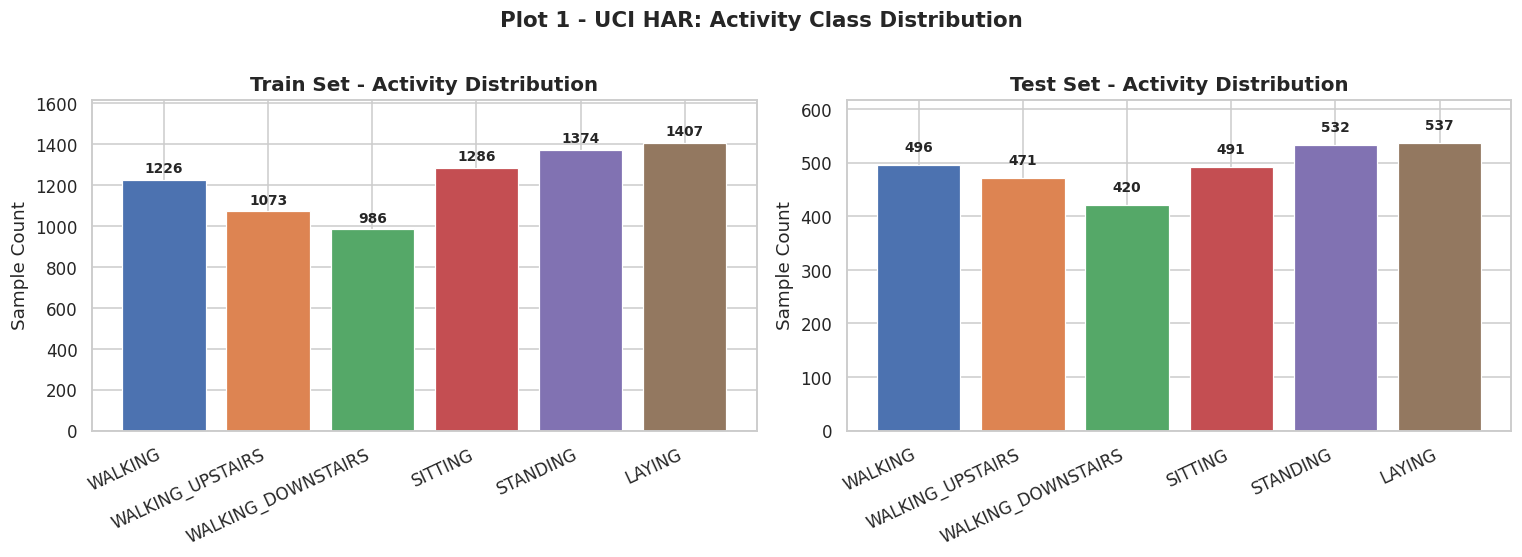

In [ ]:
# Plot 1: Activity Class Distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (split_y, split_name) in zip(axes, [(y_train, 'Train'), (y_test, 'Test')]):
    counts = [np.sum(split_y == c) for c in range(6)]
    bars   = ax.bar(ACTIVITY_NAMES, counts, color=palette, edgecolor='white', linewidth=0.8)
    ax.set_title(f'{split_name} Set - Activity Distribution', fontsize=13, fontweight='bold')
    ax.set_ylabel('Sample Count')
    ax.set_xticks(range(len(ACTIVITY_NAMES)))
    ax.set_xticklabels(ACTIVITY_NAMES, rotation=25, ha='right')
    for bar, cnt in zip(bars, counts):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20,
                f'{cnt}', ha='center', va='bottom', fontsize=9, fontweight='bold')
    ax.set_ylim(0, max(counts)*1.15)

plt.suptitle('Plot 1 - UCI HAR: Activity Class Distribution', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
save_fig('01_activity_distribution')

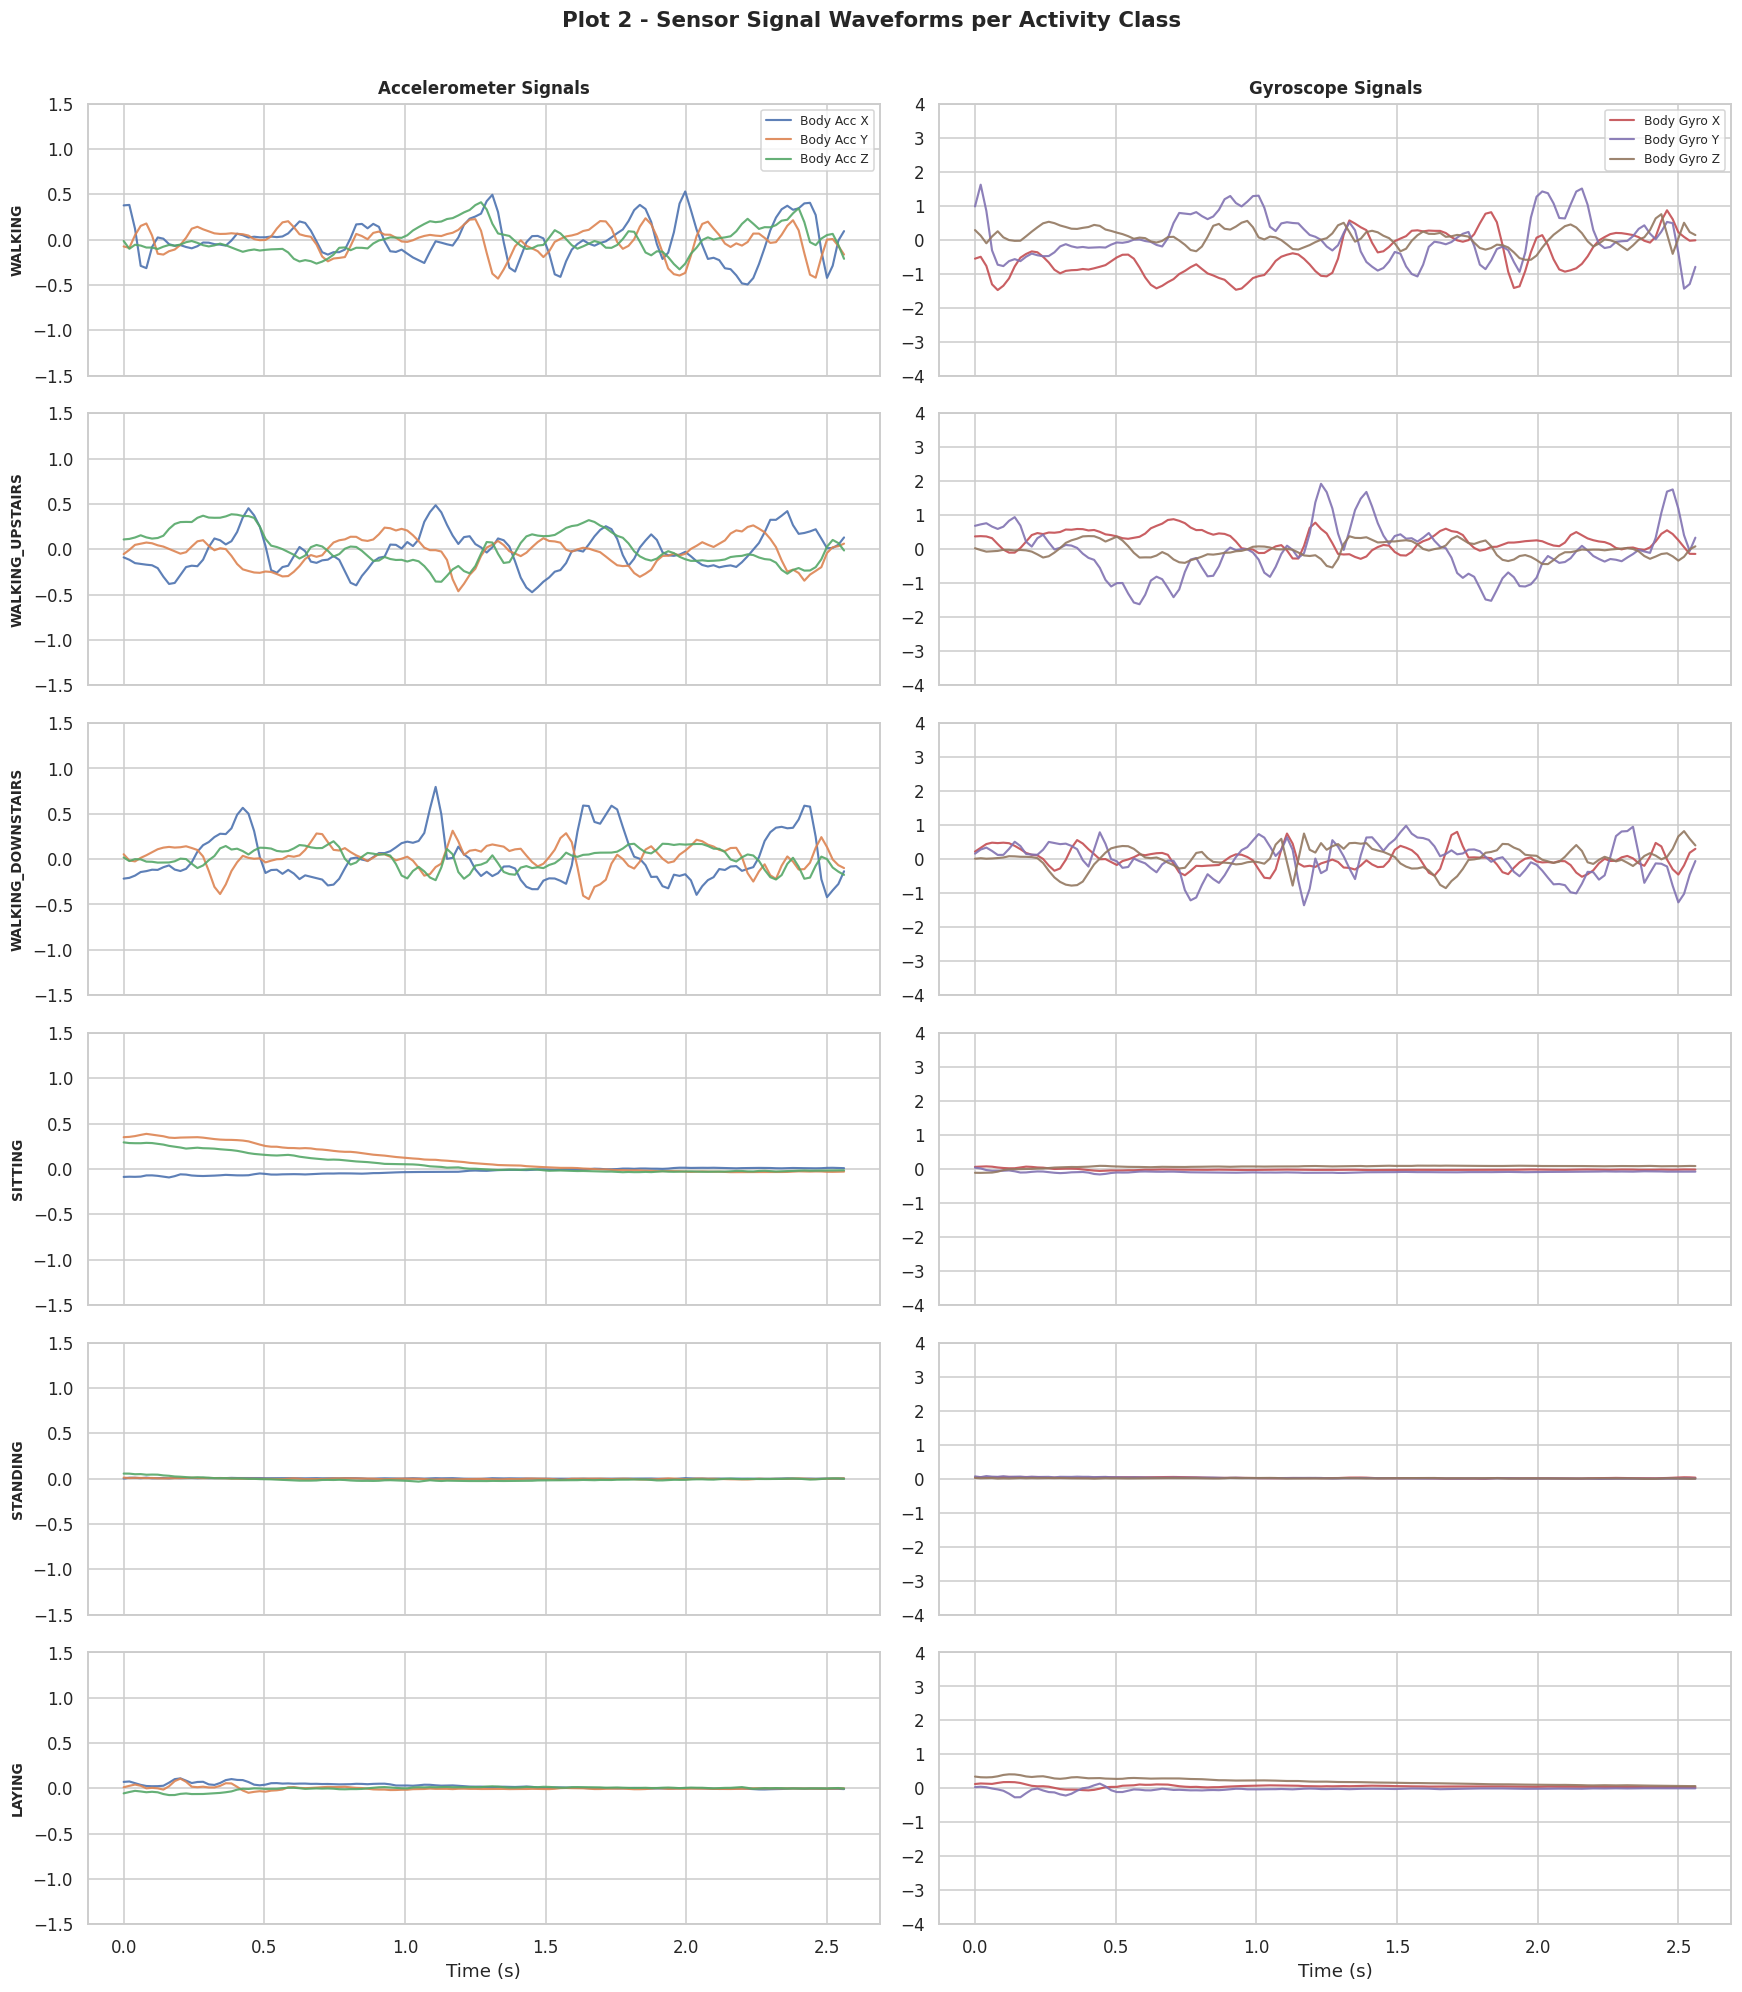

In [ ]:
# Plot 2: Sensor Signal Waveform
channel_names = [
    'body_acc_x', 'body_acc_y', 'body_acc_z',
    'body_gyro_x', 'body_gyro_y', 'body_gyro_z',
    'total_acc_x', 'total_acc_y', 'total_acc_z',
]
select_channels = [0, 1, 2, 3, 4, 5]

fig, axes = plt.subplots(6,2,figsize=(16, 18))
t_axis = np.linspace(0, 2.56, 128)

for row, cls in enumerate(range(6)):
    idx = np.where(y_train == cls)[0][0]
    sample = X_train_raw[idx]
    ax_acc  = axes[row, 0]
    ax_gyro = axes[row, 1]

    for ch, (label, lc) in enumerate(zip(
            ['Body Acc X','Body Acc Y','Body Acc Z'], ['#4C72B0','#DD8452','#55A868'])):
        ax_acc.plot(t_axis, sample[:, ch], label=label, color=lc, lw=1.4, alpha=0.9)

    for ch, (label, lc) in enumerate(zip(
            ['Body Gyro X','Body Gyro Y','Body Gyro Z'], ['#C44E52','#8172B2','#937860'])):
        ax_gyro.plot(t_axis, sample[:, ch+3], label=label, color=lc, lw=1.4, alpha=0.9)

    ax_acc.set_ylabel(ACTIVITY_NAMES[cls], fontsize=9, fontweight='bold', rotation=90,
                      labelpad=5)
    ax_acc.set_ylim(-1.5, 1.5)
    ax_gyro.set_ylim(-4, 4)
    if row == 0:
        ax_acc.set_title('Accelerometer Signals', fontsize=11, fontweight='bold')
        ax_gyro.set_title('Gyroscope Signals', fontsize=11, fontweight='bold')
    if row < 5:
        ax_acc.set_xticklabels([]); ax_gyro.set_xticklabels([])
    else:
        ax_acc.set_xlabel('Time (s)'); ax_gyro.set_xlabel('Time (s)')

axes[0, 0].legend(fontsize=8, loc='upper right')
axes[0, 1].legend(fontsize=8, loc='upper right')
plt.suptitle('Plot 2 - Sensor Signal Waveforms per Activity Class', fontsize=14,
             fontweight='bold', y=1.005)
plt.tight_layout()
save_fig('02_signal_waveforms')

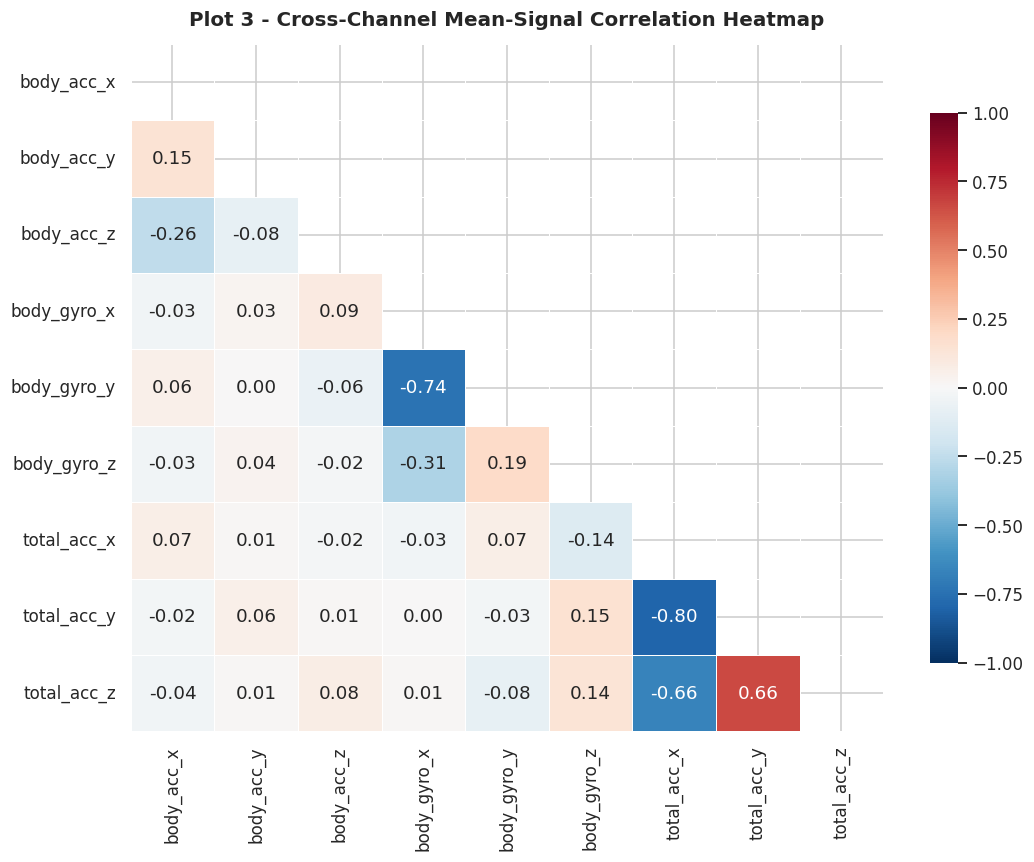

In [ ]:
# Plot 3: Cross-Channel Correlation Heatmap
mean_per_channel = X_train_raw.mean(axis=1)           # (N, 9)
corr_df = pd.DataFrame(mean_per_channel, columns=channel_names)

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_df.corr(), dtype=bool))
sns.heatmap(
    corr_df.corr(), mask=mask, annot=True, fmt='.2f',
    cmap='RdBu_r', center=0, vmin=-1, vmax=1,
    linewidths=0.5, ax=ax, cbar_kws={'shrink': 0.8}
)
ax.set_title('Plot 3 - Cross-Channel Mean-Signal Correlation Heatmap',
             fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
save_fig('03_correlation_heatmap')

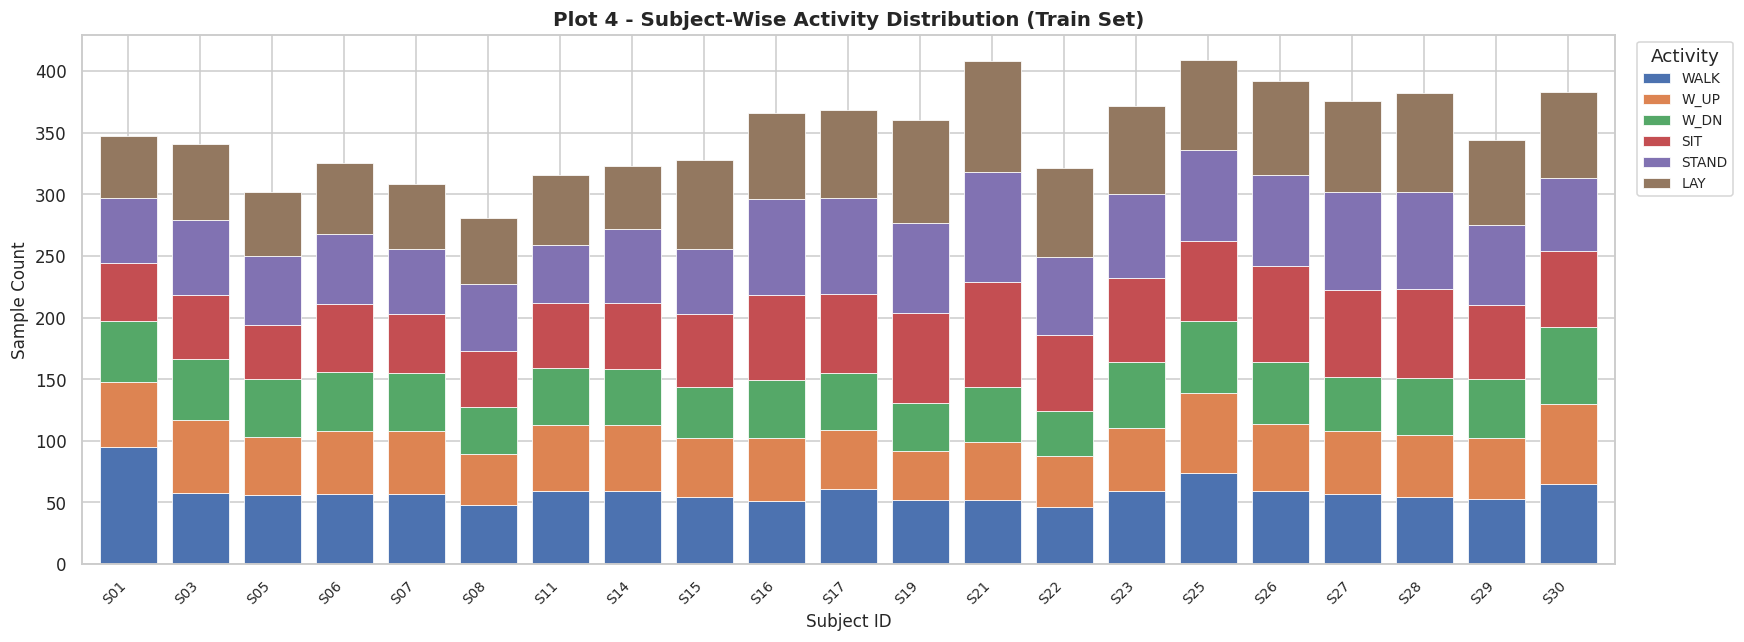

In [ ]:
# Plot 4: Subject-Wise Activity Distribution
subj_ids = np.unique(subj_train)
act_matrix = np.zeros((len(subj_ids), 6), dtype=int)

for i, sid in enumerate(subj_ids):
    mask = subj_train == sid
    for cls in range(6):
        act_matrix[i, cls] = np.sum(y_train[mask] == cls)

df_subj = pd.DataFrame(act_matrix, index=[f'S{s:02d}' for s in subj_ids],
                        columns=SHORT_LABELS)

fig, ax = plt.subplots(figsize=(16, 6))
df_subj.plot(kind='bar', stacked=True, ax=ax, color=palette, edgecolor='white',
             linewidth=0.5, width=0.8)
ax.set_xlabel('Subject ID', fontsize=11)
ax.set_ylabel('Sample Count', fontsize=11)
ax.set_title('Plot 4 - Subject-Wise Activity Distribution (Train Set)',
             fontsize=13, fontweight='bold')
ax.legend(title='Activity', bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=9)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=9)
plt.tight_layout()
save_fig('04_subject_activity_distribution')

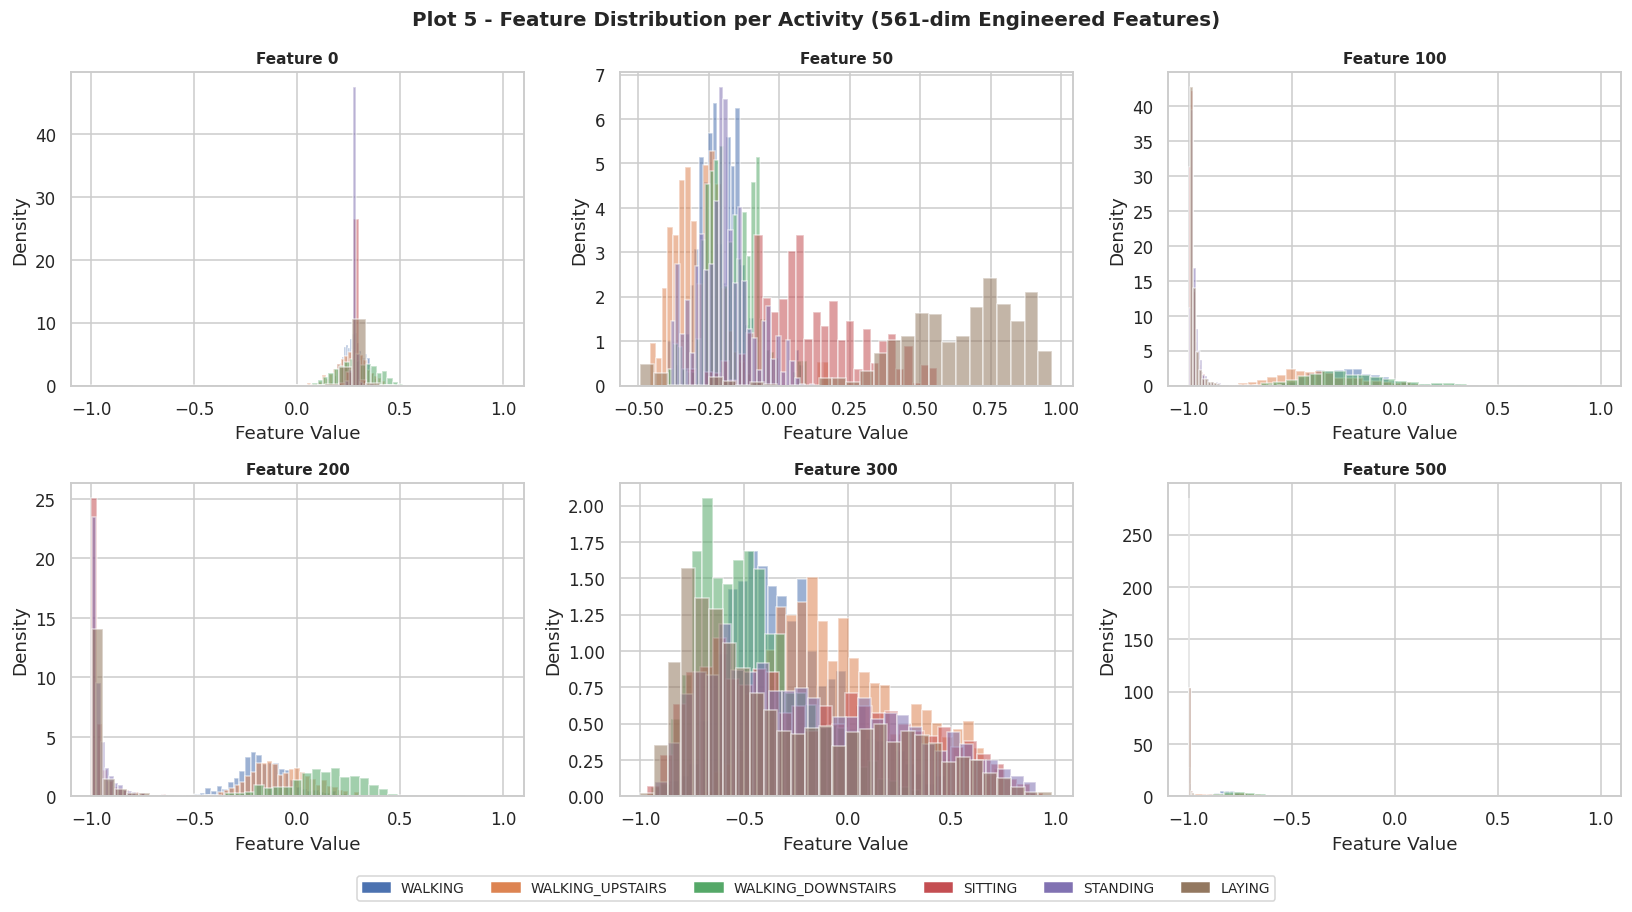

In [ ]:
# Plot 5: Feature Distribution Histograms
selected_feat_indices = [0, 50, 100, 200, 300, 500]
feat_labels = [f'Feature {i}' for i in selected_feat_indices]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for ax, feat_idx, feat_lbl in zip(axes, selected_feat_indices, feat_labels):
    for cls in range(6):
        mask = y_train == cls
        ax.hist(X_train_feat[mask, feat_idx], bins=30, alpha=0.55,
                color=palette[cls], label=ACTIVITY_NAMES[cls], density=True)
    ax.set_title(feat_lbl, fontsize=10, fontweight='bold')
    ax.set_xlabel('Feature Value')
    ax.set_ylabel('Density')

handles = [mpatches.Patch(color=palette[c], label=ACTIVITY_NAMES[c]) for c in range(6)]
fig.legend(handles=handles, loc='lower center', ncol=6, fontsize=9,
           bbox_to_anchor=(0.5, -0.04))
plt.suptitle('Plot 5 - Feature Distribution per Activity (561-dim Engineered Features)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
save_fig('05_feature_distributions')

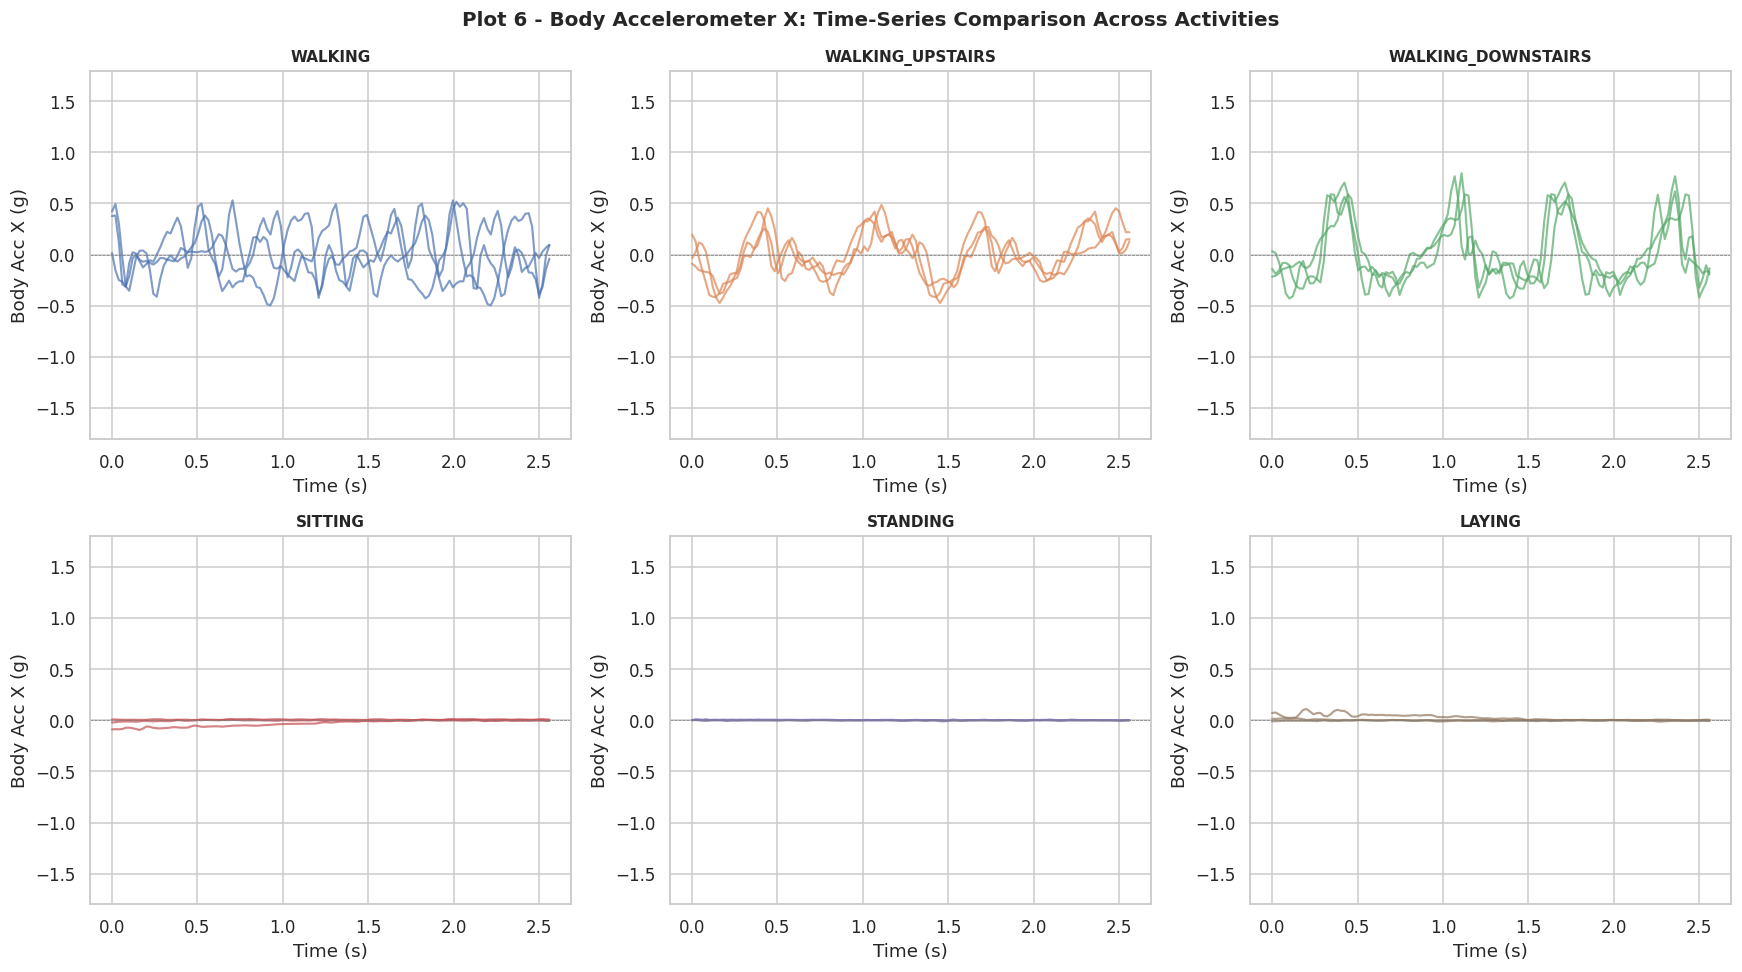

In [ ]:
# Plot 6: Time-Series Signal Comparison
N_EXAMPLES = 3
COMPARE_CH  = 0
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for cls in range(6):
    ax = axes[cls]
    cls_idx = np.where(y_train == cls)[0][:N_EXAMPLES]
    for k, idx in enumerate(cls_idx):
        ax.plot(t_axis, X_train_raw[idx, :, COMPARE_CH],
                color=palette[cls], alpha=0.7, lw=1.4,
                label='Sample' if k == 0 else '_nolegend_')
    ax.set_title(ACTIVITY_NAMES[cls], fontsize=10, fontweight='bold')
    ax.set_ylim(-1.8, 1.8)
    ax.set_xlabel('Time (s)')
    ax.set_ylabel('Body Acc X (g)')
    ax.axhline(0, color='grey', lw=0.5, linestyle='--')

plt.suptitle('Plot 6 - Body Accelerometer X: Time-Series Comparison Across Activities',
             fontsize=13, fontweight='bold')
plt.tight_layout()
save_fig('06_timeseries_comparison')

# Data Preprocessing

In [ ]:
# Subject-Aware Train-Validation Split
train_subjects = np.unique(subj_train)
n_val_subjects = max(2, int(len(train_subjects) * configuration['val_split']))

rng_split = np.random.default_rng(SEED)
val_subjects = rng_split.choice(train_subjects, size=n_val_subjects, replace=False)
tr_subjects  = np.setdiff1d(train_subjects, val_subjects)

tr_mask  = np.isin(subj_train, tr_subjects)
val_mask = np.isin(subj_train, val_subjects)

X_tr_raw  = X_train_raw[tr_mask]
y_tr      = y_train[tr_mask]
X_val_raw = X_train_raw[val_mask]
y_val     = y_train[val_mask]

print(f"Train subjects  ({len(tr_subjects):2d}): {sorted(tr_subjects)}")
print(f"Val   subjects  ({len(val_subjects):2d}): {sorted(val_subjects)}")
print(f"Train samples   : {X_tr_raw.shape[0]}")
print(f"Val   samples   : {X_val_raw.shape[0]}")
print(f"Test  samples   : {X_test_raw.shape[0]}")


Train subjects  (18): [np.int64(1), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(11), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(19), np.int64(21), np.int64(23), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30)]
Val   subjects  ( 3): [np.int64(3), np.int64(22), np.int64(25)]
Train samples   : 6281
Val   samples   : 1071
Test  samples   : 2947


In [ ]:
# Z-Score Normalization
N_tr, T, C = X_tr_raw.shape

scaler = StandardScaler()
X_tr_scaled  = scaler.fit_transform(X_tr_raw.reshape(-1, C)).reshape(N_tr, T, C)

N_val = X_val_raw.shape[0]
X_val_scaled = scaler.transform(X_val_raw.reshape(-1, C)).reshape(N_val, T, C)

N_te = X_test_raw.shape[0]
X_te_scaled  = scaler.transform(X_test_raw.reshape(-1, C)).reshape(N_te, T, C)

print("Normalisation complete.")
print(f"  Train - mean: {X_tr_scaled.mean():.4f}  std: {X_tr_scaled.std():.4f}")
print(f"  Val   - mean: {X_val_scaled.mean():.4f}  std: {X_val_scaled.std():.4f}")
print(f"  Test  - mean: {X_te_scaled.mean():.4f}  std: {X_te_scaled.std():.4f}")


Normalisation complete.
  Train - mean: -0.0000  std: 1.0000
  Val   - mean: 0.0369  std: 0.9158
  Test  - mean: -0.0019  std: 0.9436


In [ ]:
# Label encoding
y_tr_oh  = y_tr.astype(np.int64)
y_val_oh = y_val.astype(np.int64)
y_te_oh  = y_test.astype(np.int64)

print(f"y_tr_oh  shape : {y_tr_oh.shape}")
print(f"y_val_oh shape : {y_val_oh.shape}")
print(f"y_te_oh  shape : {y_te_oh.shape}")

y_tr_oh  shape : (6281,)
y_val_oh shape : (1071,)
y_te_oh  shape : (2947,)


In [ ]:
# Data Augmentation
def augment_signals(X, y, noise_std=0.02, time_warp_max=0.05, aug_fraction=0.3, seed=42):
    rng = np.random.default_rng(seed)
    N, T, C = X.shape
    n_aug = int(N * aug_fraction)

    aug_idx = rng.choice(N, size=n_aug, replace=False)

    X_to_augment = X[aug_idx].copy()
    y_to_augment = y[aug_idx].copy()

    half_aug = n_aug // 2

    # 1. Apply Gaussian noise to the first half of selected samples
    X_to_augment[:half_aug] += noise_std * rng.standard_normal(X_to_augment[:half_aug].shape)

    # 2. Apply Time Warping to the second half of selected samples
    orig_t = np.linspace(0, 1, T)
    for i in range(half_aug, n_aug):
        distortion = rng.uniform(-time_warp_max, time_warp_max, size=T)
        warped_t = orig_t + np.cumsum(distortion)
        warped_t = (warped_t - warped_t[0]) / (warped_t[-1] - warped_t[0])

        for ch in range(C):
            X_to_augment[i, :, ch] = np.interp(orig_t, warped_t, X_to_augment[i, :, ch])

    X_augmented_combined = np.concatenate([X, X_to_augment], axis=0)
    y_augmented_combined = np.concatenate([y, y_to_augment], axis=0)

    return X_augmented_combined, y_augmented_combined

X_tr_aug, y_tr_aug = augment_signals(X_tr_scaled, y_tr, aug_fraction=0.3, seed=SEED)

X_tr_aug = X_tr_aug.astype(np.float32)
y_tr_aug_oh = y_tr_aug.astype(np.int64)

In [ ]:
# Dataset Pipeline
BATCH = configuration['batch_size']

def make_dataloader(X, y, batch_size, shuffle=False):
    X_t = torch.tensor(X, dtype=torch.float32)

    if len(y.shape) > 1 and y.shape[1] > 1:
        y_indices = np.argmax(y, axis=1)
        y_t = torch.tensor(y_indices, dtype=torch.long)
    else:
        y_t = torch.tensor(y, dtype=torch.long)

    dataset = TensorDataset(X_t, y_t)

    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=0,
        pin_memory=True if DEVICE.type == 'cuda' else False
    )

train_ds = make_dataloader(X_tr_aug.astype(np.float32),   y_tr_aug_oh, BATCH, shuffle=True)
val_ds   = make_dataloader(X_val_scaled.astype(np.float32), y_val_oh,   BATCH, shuffle=False)
test_ds  = make_dataloader(X_te_scaled.astype(np.float32),  y_te_oh,    BATCH, shuffle=False)

print("PyTorch DataLoader pipelines ready.")
print(f"  Train batches : {len(train_ds)} (Total samples: {len(train_ds.dataset)})")
print(f"  Val   batches : {len(val_ds)} (Total samples: {len(val_ds.dataset)})")
print(f"  Test  batches : {len(test_ds)} (Total samples: {len(test_ds.dataset)})")

PyTorch DataLoader pipelines ready.
  Train batches : 128 (Total samples: 8165)
  Val   batches : 17 (Total samples: 1071)
  Test  batches : 47 (Total samples: 2947)


# Model Architecture

In [ ]:
class RNNModel(nn.Module):
    def __init__(self, n_timesteps=128, n_channels=9, n_classes=6,
                 hidden_units=32, n_layers=2, dropout_rate=0.5):
        super().__init__()

        rnn_dropout = dropout_rate if n_layers > 1 else 0.0

        self.rnn = nn.RNN(
            input_size=n_channels,
            hidden_size=hidden_units,
            num_layers=n_layers,
            batch_first=True,
            bidirectional=True,
            dropout=rnn_dropout,
            nonlinearity='tanh'
        )

        rnn_out_size = hidden_units * 2
        self.layer_norm = nn.LayerNorm(rnn_out_size)

        self.input_dropout = nn.Dropout(dropout_rate)
        self.dropout_rnn = nn.Dropout(dropout_rate)
        self.dense_hidden = nn.Linear(rnn_out_size, 128)
        self.relu = nn.ReLU()
        self.dropout_dense = nn.Dropout(dropout_rate)
        self.output = nn.Linear(128, n_classes)

    def forward(self, x):
        x = self.input_dropout(x)
        out, _ = self.rnn(x)
        out = out.mean(dim=1)

        out = self.layer_norm(out)
        out = self.dropout_rnn(out)
        out = self.relu(self.dense_hidden(out))
        out = self.dropout_dense(out)
        return self.output(out)


class LSTMModel(nn.Module):
    def __init__(self, n_timesteps=128, n_channels=9, n_classes=6,
                 hidden_units=32, n_layers=2, dropout_rate=0.5):
        super().__init__()

        lstm_dropout = dropout_rate if n_layers > 1 else 0.0

        self.lstm = nn.LSTM(
            input_size=n_channels,
            hidden_size=hidden_units,
            num_layers=n_layers,
            batch_first=True,
            bidirectional=True,
            dropout=lstm_dropout
        )

        lstm_out_size = hidden_units * 2
        self.layer_norm = nn.LayerNorm(lstm_out_size)

        self.input_dropout = nn.Dropout(dropout_rate)
        self.dropout_lstm = nn.Dropout(dropout_rate)
        self.dense_hidden = nn.Linear(lstm_out_size, 128)
        self.relu = nn.ReLU()
        self.dropout_dense = nn.Dropout(dropout_rate)
        self.output = nn.Linear(128, n_classes)

    def forward(self, x):
        x = self.input_dropout(x)
        out, _ = self.lstm(x)

        out = out.mean(dim=1)
        out = self.layer_norm(out)
        out = self.dropout_lstm(out)
        out = self.relu(self.dense_hidden(out))
        out = self.dropout_dense(out)
        return self.output(out)


def build_rnn(n_timesteps=128, n_channels=9, n_classes=6,
              hidden_units=32, n_layers=2, dropout_rate=0.4, lr=1e-4):
    model = RNNModel(n_timesteps, n_channels, n_classes,
                     hidden_units, n_layers, dropout_rate).to(DEVICE)
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-3)
    return model, optimizer


def build_lstm(n_timesteps=128, n_channels=9, n_classes=6,
               hidden_units=32, n_layers=2, dropout_rate=0.4, lr=1e-4):
    model = LSTMModel(n_timesteps, n_channels, n_classes,
                      hidden_units, n_layers, dropout_rate).to(DEVICE)
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-3)
    return model, optimizer

# Model Training

In [ ]:
# Training Utilities
criterion = nn.CrossEntropyLoss()
GRAD_CLIP_NORM = 1.0

class EarlyStopping:
    def __init__(self, patience=2, restore_best_weights=True, verbose=1, monitor='val_loss'):
        self.patience = patience
        self.restore_best_weights = restore_best_weights
        self.verbose = verbose
        self.monitor = monitor
        self.maximize = monitor in ['val_accuracy', 'val_f1']
        self.best_val = float('-inf') if self.maximize else float('inf')
        self.counter = 0
        self.best_weights = None
        self.stopped_epoch = 0
        self.best_epoch = 0

    def __call__(self, val_metric, model, epoch):
        improved = val_metric > self.best_val if self.maximize else val_metric < self.best_val

        if improved:
            self.best_val = val_metric
            self.counter = 0
            self.best_epoch = epoch

            if self.restore_best_weights:
                import copy
                self.best_weights = copy.deepcopy(model.state_dict())
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.stopped_epoch = epoch
                if self.restore_best_weights and self.best_weights is not None:
                    model.load_state_dict(self.best_weights)
                    if self.verbose:
                        print(f"Restoring best weights from epoch {self.best_epoch}")
                return True
        return False


def get_callbacks(model_name, monitor='val_loss'):
    os.makedirs('checkpoints', exist_ok=True)
    early_stop = EarlyStopping(
        patience=10,
        restore_best_weights=True,
        verbose=1,
        monitor=monitor
    )
    return early_stop


def train_one_epoch(model, optimizer, dataloader):
    model.train()
    total_loss, correct, total = 0.0, 0, 0

    for X_batch, y_batch in dataloader:
        X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)

        optimizer.zero_grad()
        logits = model(X_batch)
        loss = criterion(logits, y_batch)

        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP_NORM)
        optimizer.step()

        total_loss += loss.item() * len(y_batch)
        correct += (logits.argmax(1) == y_batch).sum().item()
        total += len(y_batch)

    return total_loss / total, correct / total


def evaluate_epoch(model, dataloader):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0

    with torch.no_grad():
        for X_batch, y_batch in dataloader:
            X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)

            logits = model(X_batch)
            loss = criterion(logits, y_batch)

            total_loss += loss.item() * len(y_batch)
            correct += (logits.argmax(1) == y_batch).sum().item()
            total += len(y_batch)

    return total_loss / total, correct / total


def compute_macro_f1(model, val_loader):
    model.eval()
    all_preds = []
    all_true = []

    with torch.no_grad():
        for x, y in val_loader:
            x = x.to(DEVICE)
            logits = model(x)
            preds = torch.argmax(logits, dim=1).cpu().numpy()

            all_preds.extend(preds)
            all_true.extend(y.cpu().numpy())

    return f1_score(all_true, all_preds, average='macro')


def train_model(model, optimizer, train_ds, val_ds, epochs, early_stop_cb,
                lr_scheduler=None, verbose=1):

    history = {
        'loss': [],
        'accuracy': [],
        'val_loss': [],
        'val_accuracy': [],
        'val_f1': []
    }

    for epoch in range(1, epochs + 1):
        tr_loss, tr_acc = train_one_epoch(model, optimizer, train_ds)
        val_loss, val_acc = evaluate_epoch(model, val_ds)
        val_f1 = compute_macro_f1(model, val_ds)

        history['loss'].append(tr_loss)
        history['accuracy'].append(tr_acc)
        history['val_loss'].append(val_loss)
        history['val_accuracy'].append(val_acc)
        history['val_f1'].append(val_f1)

        if lr_scheduler is not None:
            lr_scheduler.step(val_loss)

        if verbose:
            print(
                f"Epoch {epoch:3d}/{epochs} | "
                f"loss={tr_loss:.4f} acc={tr_acc:.4f} | "
                f"val_loss={val_loss:.4f} val_acc={val_acc:.4f} val_f1={val_f1:.4f}"
            )

        if early_stop_cb.monitor == 'val_accuracy':
            es_metric = val_acc
        elif early_stop_cb.monitor == 'val_loss':
            es_metric = val_loss
        elif early_stop_cb.monitor == 'val_f1':
            es_metric = val_f1
        else:
            raise ValueError(f"Unknown monitor: {early_stop_cb.monitor}")

        if early_stop_cb(es_metric, model, epoch):
            if verbose:
                print(f"Early stopping at epoch {epoch}.")
            break

    return history


def plot_training_history(hist_rnn, hist_lstm, fig_name=None):

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(hist_rnn['loss'], label='RNN Train', lw=2)
    plt.plot(hist_rnn['val_loss'], label='RNN Val', lw=2, linestyle='--')

    plt.plot(hist_lstm['loss'], label='LSTM Train', lw=2)
    plt.plot(hist_lstm['val_loss'], label='LSTM Val', lw=2, linestyle='--')

    plt.title('Loss Curves (RNN vs LSTM)')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.grid(alpha=0.4)
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(hist_rnn['accuracy'], label='RNN Train', lw=2)
    plt.plot(hist_rnn['val_accuracy'], label='RNN Val', lw=2, linestyle='--')

    plt.plot(hist_lstm['accuracy'], label='LSTM Train', lw=2)
    plt.plot(hist_lstm['val_accuracy'], label='LSTM Val', lw=2, linestyle='--')

    plt.title('Accuracy Curves (RNN vs LSTM)')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.grid(alpha=0.4)
    plt.legend()

    title = 'RNN vs LSTM Training Performance'

    if fig_name == '07_training_curves':
        title = 'Plot 7 - Baseline Training Curves: RNN vs LSTM'

    elif fig_name == '08_training_curves':
        title = 'Plot 8 - Final Training Curves: RNN vs LSTM'

    plt.suptitle(title, fontsize=14, fontweight='bold')

    plt.tight_layout()

    if fig_name:
        save_fig(fig_name)
    else:
        plt.show()

In [ ]:
# Train RNN
print("Training RNN...")
t0 = time.time()

rnn_model, rnn_optimizer = build_rnn(
    hidden_units=configuration['hidden_units'],
    n_layers=configuration['n_layers'],
    dropout_rate=configuration['dropout_rate'],
    lr=configuration['learning_rate']
)

rnn_scheduler = ReduceLROnPlateau(
    rnn_optimizer,
    mode='min',
    factor=0.5,
    patience=3,
)

rnn_callbacks = get_callbacks('rnn_model', monitor='val_loss')

rnn_history = train_model(
    model=rnn_model,
    optimizer=rnn_optimizer,
    train_ds=train_ds,
    val_ds=val_ds,
    epochs=configuration['epochs'],
    early_stop_cb=rnn_callbacks,
    lr_scheduler=rnn_scheduler,
    verbose=1
)

rnn_train_time = time.time() - t0
print(f"\nRNN training complete in {rnn_train_time:.1f}s  |  "
      f"Best val accuracy: {max(rnn_history['val_accuracy']):.4f}")

Training RNN...
Epoch   1/50 | loss=1.6585 acc=0.3025 | val_loss=1.3543 val_acc=0.4388 val_f1=0.3036
Epoch   2/50 | loss=1.3107 acc=0.4720 | val_loss=1.0809 val_acc=0.6144 val_f1=0.5520
Epoch   3/50 | loss=1.0232 acc=0.5995 | val_loss=0.8512 val_acc=0.7208 val_f1=0.6857
Epoch   4/50 | loss=0.8250 acc=0.6639 | val_loss=0.7289 val_acc=0.7488 val_f1=0.7200
Epoch   5/50 | loss=0.7234 acc=0.7039 | val_loss=0.6681 val_acc=0.7675 val_f1=0.7518
Epoch   6/50 | loss=0.6484 acc=0.7346 | val_loss=0.6019 val_acc=0.7918 val_f1=0.7813
Epoch   7/50 | loss=0.5906 acc=0.7623 | val_loss=0.5311 val_acc=0.7983 val_f1=0.7880
Epoch   8/50 | loss=0.5452 acc=0.7831 | val_loss=0.4763 val_acc=0.7983 val_f1=0.7907
Epoch   9/50 | loss=0.5005 acc=0.8094 | val_loss=0.3773 val_acc=0.8655 val_f1=0.8600
Epoch  10/50 | loss=0.4795 acc=0.8185 | val_loss=0.3906 val_acc=0.8515 val_f1=0.8469
Epoch  11/50 | loss=0.4472 acc=0.8320 | val_loss=0.3427 val_acc=0.8796 val_f1=0.8764
Epoch  12/50 | loss=0.4142 acc=0.8404 | val_loss=

In [ ]:
# Train LSTM
print("\nTraining LSTM ...")
t0 = time.time()

lstm_model, lstm_optimizer = build_lstm(
    hidden_units=configuration['hidden_units'],
    n_layers=configuration['n_layers'],
    dropout_rate=configuration['dropout_rate'],
    lr=configuration['learning_rate']
)

lstm_scheduler = ReduceLROnPlateau(
    lstm_optimizer,
    mode='min',
    factor=0.5,
    patience=3
)

lstm_callbacks = get_callbacks('lstm_model', monitor='val_loss')

lstm_history = train_model(
    model=lstm_model,
    optimizer=lstm_optimizer,
    train_ds=train_ds,
    val_ds=val_ds,
    epochs=configuration['epochs'],
    early_stop_cb=lstm_callbacks,
    lr_scheduler=lstm_scheduler,
    verbose=1
)

lstm_train_time = time.time() - t0
print(f"\nLSTM training complete in {lstm_train_time:.1f}s  |  "
      f"Best val accuracy: {max(lstm_history['val_accuracy']):.4f}")


Training LSTM ...
Epoch   1/50 | loss=1.7157 acc=0.2675 | val_loss=1.4473 val_acc=0.5425 val_f1=0.4405
Epoch   2/50 | loss=1.3373 acc=0.4698 | val_loss=1.0734 val_acc=0.6601 val_f1=0.5808
Epoch   3/50 | loss=0.9803 acc=0.5976 | val_loss=0.8020 val_acc=0.6909 val_f1=0.6155
Epoch   4/50 | loss=0.7672 acc=0.6606 | val_loss=0.6913 val_acc=0.7376 val_f1=0.6951
Epoch   5/50 | loss=0.6727 acc=0.7080 | val_loss=0.6194 val_acc=0.7666 val_f1=0.7423
Epoch   6/50 | loss=0.5977 acc=0.7660 | val_loss=0.5695 val_acc=0.7871 val_f1=0.7593
Epoch   7/50 | loss=0.5170 acc=0.8080 | val_loss=0.5106 val_acc=0.8002 val_f1=0.7801
Epoch   8/50 | loss=0.4380 acc=0.8495 | val_loss=0.4688 val_acc=0.8207 val_f1=0.8044
Epoch   9/50 | loss=0.3880 acc=0.8665 | val_loss=0.4753 val_acc=0.8198 val_f1=0.8061
Epoch  10/50 | loss=0.3494 acc=0.8811 | val_loss=0.4043 val_acc=0.8571 val_f1=0.8488
Epoch  11/50 | loss=0.3192 acc=0.8914 | val_loss=0.3073 val_acc=0.8880 val_f1=0.8840
Epoch  12/50 | loss=0.3027 acc=0.8911 | val_lo

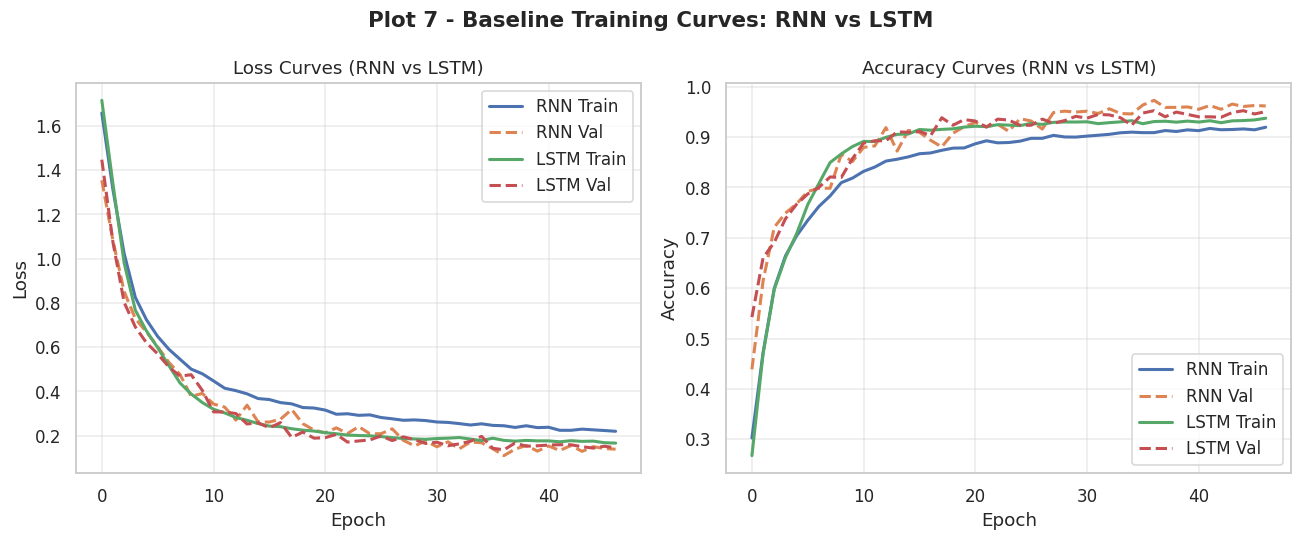

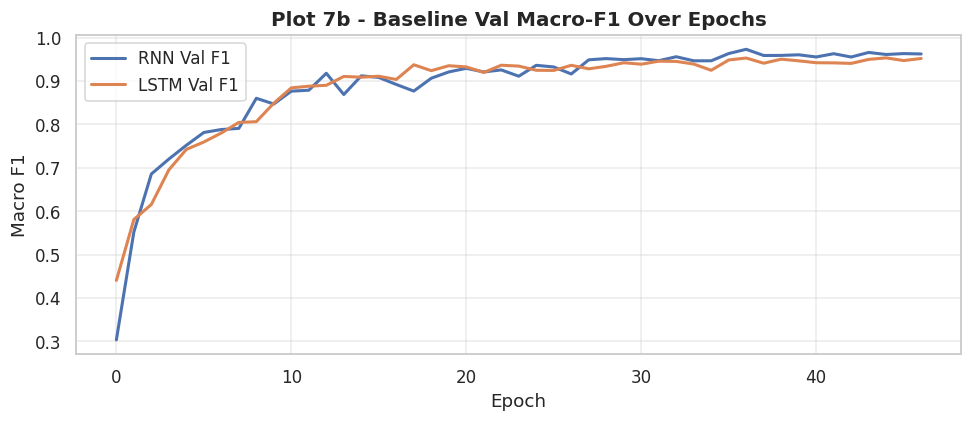

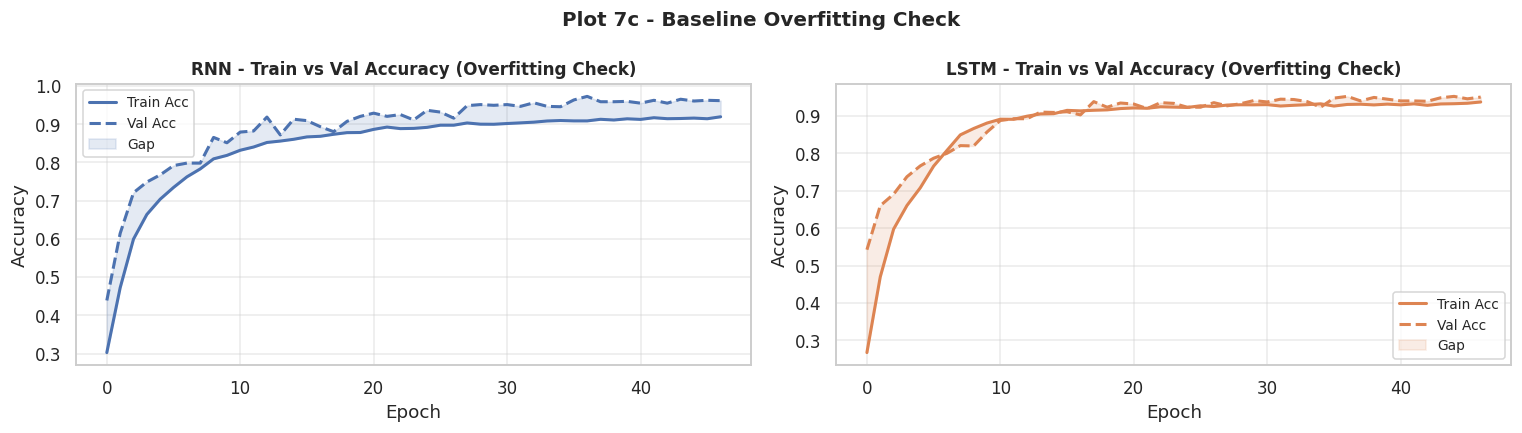

In [ ]:
# Plot 7: Baseline Training Curves (Loss & Accuracy)
plot_training_history(rnn_history, lstm_history, '07_training_curves')

# Plot 7b: Baseline Val F1 Over Epochs
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(rnn_history['val_f1'],  label='RNN Val F1',  lw=2, color='#4C72B0')
ax.plot(lstm_history['val_f1'], label='LSTM Val F1', lw=2, color='#DD8452')
ax.set_title('Plot 7b - Baseline Val Macro-F1 Over Epochs', fontsize=13, fontweight='bold')
ax.set_xlabel('Epoch')
ax.set_ylabel('Macro F1')
ax.legend()
ax.grid(alpha=0.4)
plt.tight_layout()
save_fig('07b_baseline_val_f1')

# Plot 7c: Baseline Overfitting Check (Train vs Val Gap)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for ax, hist, name, color in zip(
    axes,
    [rnn_history, lstm_history],
    ['RNN', 'LSTM'],
    ['#4C72B0', '#DD8452']
):
    gap = [tr - va for tr, va in zip(hist['accuracy'], hist['val_accuracy'])]
    ax.plot(hist['accuracy'],     label='Train Acc', lw=2, color=color)
    ax.plot(hist['val_accuracy'], label='Val Acc',   lw=2, color=color, linestyle='--')
    ax.fill_between(range(len(gap)),
                    hist['val_accuracy'],
                    hist['accuracy'],
                    alpha=0.15, color=color, label='Gap')
    ax.set_title(f'{name} - Train vs Val Accuracy (Overfitting Check)', fontsize=11, fontweight='bold')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Accuracy')
    ax.legend(fontsize=9)
    ax.grid(alpha=0.4)

plt.suptitle('Plot 7c - Baseline Overfitting Check', fontsize=13, fontweight='bold')
plt.tight_layout()
save_fig('07c_baseline_overfit_check')

## Baseline Model Evaluation

In [ ]:
def evaluate_model(model, model_name, X_test, y_test_int):
    model.eval()
    X_t = torch.tensor(X_test, dtype=torch.float32)
    with torch.no_grad():
        logits = model(X_t.to(DEVICE))
        y_pred_prob = torch.softmax(logits, dim=1).cpu().numpy()
    y_pred = np.argmax(y_pred_prob, axis=1)

    acc      = accuracy_score(y_test_int, y_pred)
    macro_f1 = f1_score(y_test_int, y_pred, average='macro')
    cm       = confusion_matrix(y_test_int, y_pred)
    report   = classification_report(y_test_int, y_pred,
                                     target_names=ACTIVITY_NAMES, digits=4)

    print(f"  {model_name}")
    print("------------------------------------------------------------")
    print(f"  Test Accuracy : {acc:.4f}")
    print(f"  Macro F1-Score: {macro_f1:.4f}")
    print(f"\nPer-Class Classification Report:\n")
    print(report)

    return acc, macro_f1, cm, y_pred

rnn_baseline_model = rnn_model
lstm_baseline_model = lstm_model

rnn_base_acc, rnn_base_f1, rnn_base_cm, rnn_base_pred = evaluate_model(
    rnn_baseline_model,
    'RNN (Baseline)',
    X_te_scaled,
    y_test
)

lstm_base_acc, lstm_base_f1, lstm_base_cm, lstm_base_pred = evaluate_model(
    lstm_baseline_model,
    'LSTM (Baseline)',
    X_te_scaled,
    y_test
)

  RNN (Baseline)
------------------------------------------------------------
  Test Accuracy : 0.8958
  Macro F1-Score: 0.8950

Per-Class Classification Report:

                    precision    recall  f1-score   support

           WALKING     0.9241    0.9577    0.9406       496
  WALKING_UPSTAIRS     0.9661    0.8471    0.9027       471
WALKING_DOWNSTAIRS     0.8745    0.9952    0.9310       420
           SITTING     0.8013    0.7800    0.7905       491
          STANDING     0.8458    0.8045    0.8247       532
            LAYING     0.9624    1.0000    0.9808       537

          accuracy                         0.8958      2947
         macro avg     0.8957    0.8974    0.8950      2947
      weighted avg     0.8961    0.8958    0.8946      2947

  LSTM (Baseline)
------------------------------------------------------------
  Test Accuracy : 0.9006
  Macro F1-Score: 0.8998

Per-Class Classification Report:

                    precision    recall  f1-score   support

         

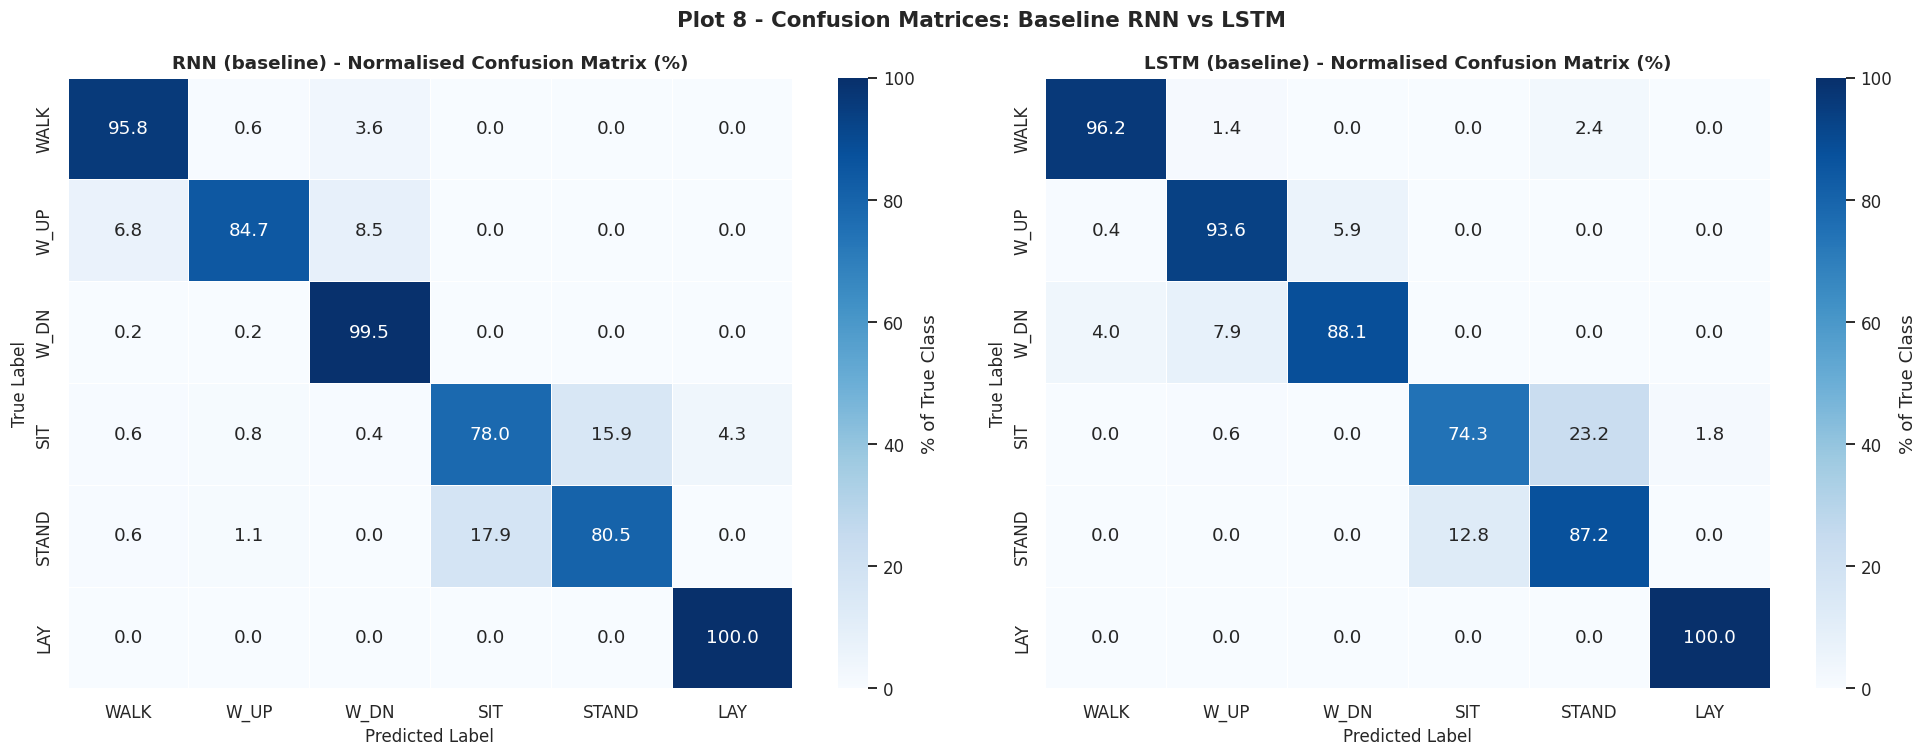

In [ ]:
# Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for ax, cm, name in zip(
    axes,
    [rnn_base_cm, lstm_base_cm],
    ['RNN (baseline)', 'LSTM (baseline)']
):
    row_sum = cm.sum(axis=1, keepdims=True)
    cm_norm = np.divide(cm, row_sum, where=row_sum != 0) * 100
    sns.heatmap(
        cm_norm,
        annot=True,
        fmt='.1f',
        cmap='Blues',
        xticklabels=SHORT_LABELS,
        yticklabels=SHORT_LABELS,
        linewidths=0.5,
        ax=ax,
        cbar_kws={'label': '% of True Class'}
    )
    ax.set_xlabel('Predicted Label', fontsize=11)
    ax.set_ylabel('True Label', fontsize=11)
    ax.set_title(f'{name} - Normalised Confusion Matrix (%)', fontsize=12, fontweight='bold')

plt.suptitle('Plot 8 - Confusion Matrices: Baseline RNN vs LSTM', fontsize=14, fontweight='bold')
plt.tight_layout()
save_fig('8_baseline_confusion_matrices')

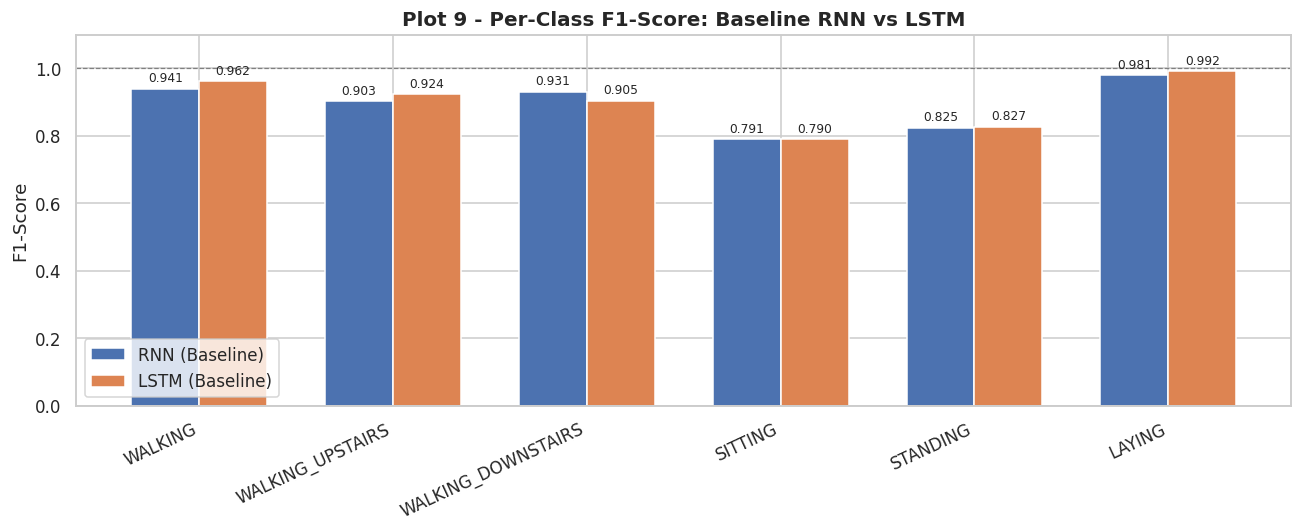

In [ ]:
# Per-class F1 Comparison Bar Chart
from sklearn.metrics import f1_score as _f1

rnn_per_class  = _f1(y_test, rnn_base_pred,  average=None)
lstm_per_class = _f1(y_test, lstm_base_pred, average=None)

x = np.arange(len(ACTIVITY_NAMES))
w = 0.35
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(x - w/2, rnn_per_class,  width=w, label='RNN (Baseline)',  color='#4C72B0', edgecolor='white')
ax.bar(x + w/2, lstm_per_class, width=w, label='LSTM (Baseline)', color='#DD8452', edgecolor='white')
ax.set_xticks(x)
ax.set_xticklabels(ACTIVITY_NAMES, rotation=25, ha='right')
ax.set_ylabel('F1-Score')
ax.set_ylim(0, 1.1)
ax.axhline(1.0, color='grey', lw=0.8, linestyle='--')
ax.legend()

for xi, (rv, lv) in enumerate(zip(rnn_per_class, lstm_per_class)):
    ax.text(xi - w/2, rv + 0.02, f'{rv:.3f}', ha='center', fontsize=8)
    ax.text(xi + w/2, lv + 0.02, f'{lv:.3f}', ha='center', fontsize=8)

ax.set_title('Plot 9 - Per-Class F1-Score: Baseline RNN vs LSTM', fontsize=13, fontweight='bold')
plt.tight_layout()
save_fig('9_baseline_per_class_f1')

# Hyperparameter Tuning

In [ ]:
# Hyperparameter Search Grid
TUNING_GRID = {
    'learning_rate': [1e-3, 5e-4, 3e-4, 1e-4],
    'hidden_units': [32, 64, 128, 256],
    'n_layers': [1, 2],
    'dropout_rate': [0.2, 0.3, 0.4, 0.5],
    'batch_size': [32, 64, 128],
    'weight_decay': [0.0, 1e-4, 5e-4],
}

from itertools import product

keys = list(TUNING_GRID.keys())
all_combos = list(product(*TUNING_GRID.values()))

MAX_COMBOS = 5
if len(all_combos) > MAX_COMBOS:
    combos = random.sample(all_combos, MAX_COMBOS)
else:
    combos = all_combos

print(f"Total tuning runs: {len(combos)}")


Total tuning runs: 5


In [ ]:
# Grid Search Loop
tuning_results = []
TUNING_EPOCHS = configuration['tuning_epochs']

def make_tuning_ds(batch_size):
    tr = make_dataloader(X_tr_aug.astype(np.float32), y_tr_aug_oh, batch_size, shuffle=True)
    va = make_dataloader(X_val_scaled.astype(np.float32), y_val_oh, batch_size, shuffle=False)
    return tr, va

for arch_name, builder in [('RNN', build_rnn), ('LSTM', build_lstm)]:
    print(f"Tuning {arch_name}")

    best_val_loss = float('inf')
    best_cfg = None

    for i, combo in enumerate(combos):
        params = dict(zip(keys, combo))
        print(f"[{i+1}/{len(combos)}] {params}", end=' , ')

        t_ds, v_ds = make_tuning_ds(params['batch_size'])

        model, opt = builder(
            hidden_units=params['hidden_units'],
            n_layers=params['n_layers'],
            dropout_rate=params['dropout_rate'],
            lr=params['learning_rate']
        )

        for group in opt.param_groups:
            group['weight_decay'] = params['weight_decay']

        sched = optim.lr_scheduler.ReduceLROnPlateau(opt, mode='min', factor=0.5, patience=3)

        early_stop = EarlyStopping(
            patience=3,
            restore_best_weights=True,
            verbose=0,
            monitor='val_loss'
        )

        history = train_model(
            model, opt, t_ds, v_ds,
            epochs=TUNING_EPOCHS,
            early_stop_cb=early_stop,
            lr_scheduler=sched,
            verbose=0
        )

        val_loss, val_acc = evaluate_epoch(model, v_ds)
        history_val_loss = history['val_loss'] if isinstance(history, dict) else history.history['val_loss']
        stable_val_loss = np.mean(history_val_loss[-3:])
        val_f1 = np.mean(history['val_f1'][-3:])

        print(f"val_loss={stable_val_loss:.4f} val_acc={val_acc:.4f} val_f1={val_f1:.4f}")

        tuning_results.append({
            'arch': arch_name,
            **params,
            'val_loss': stable_val_loss,
            'val_acc': val_acc,
            'val_f1': val_f1
        })

        if stable_val_loss < best_val_loss:
            best_val_loss = stable_val_loss
            best_cfg = params.copy()
            torch.save(model.state_dict(), f'best_{arch_name}.pt')

    print(f"\nBest {arch_name} config (lowest val_loss): {best_cfg} -> val_loss = {best_val_loss:.4f}\n")

df_tuning = pd.DataFrame(tuning_results)
df_tuning.sort_values(['arch','val_loss'], ascending=[True, True], inplace=True)
df_tuning.reset_index(drop=True, inplace=True)

Tuning RNN
[1/5] {'learning_rate': 0.001, 'hidden_units': 256, 'n_layers': 1, 'dropout_rate': 0.3, 'batch_size': 64, 'weight_decay': 0.0} , val_loss=0.2099 val_acc=0.9617 val_f1=0.9308
[2/5] {'learning_rate': 0.001, 'hidden_units': 32, 'n_layers': 2, 'dropout_rate': 0.3, 'batch_size': 128, 'weight_decay': 0.0} , val_loss=0.1108 val_acc=0.9776 val_f1=0.9589
[3/5] {'learning_rate': 0.0005, 'hidden_units': 256, 'n_layers': 2, 'dropout_rate': 0.4, 'batch_size': 64, 'weight_decay': 0.0005} , val_loss=0.1069 val_acc=0.9692 val_f1=0.9609
[4/5] {'learning_rate': 0.0005, 'hidden_units': 128, 'n_layers': 2, 'dropout_rate': 0.5, 'batch_size': 128, 'weight_decay': 0.0} , val_loss=0.0842 val_acc=0.9851 val_f1=0.9732
[5/5] {'learning_rate': 0.0005, 'hidden_units': 128, 'n_layers': 1, 'dropout_rate': 0.4, 'batch_size': 128, 'weight_decay': 0.0001} , val_loss=0.0815 val_acc=0.9935 val_f1=0.9736

Best RNN config (lowest val_loss): {'learning_rate': 0.0005, 'hidden_units': 128, 'n_layers': 1, 'dropout_r

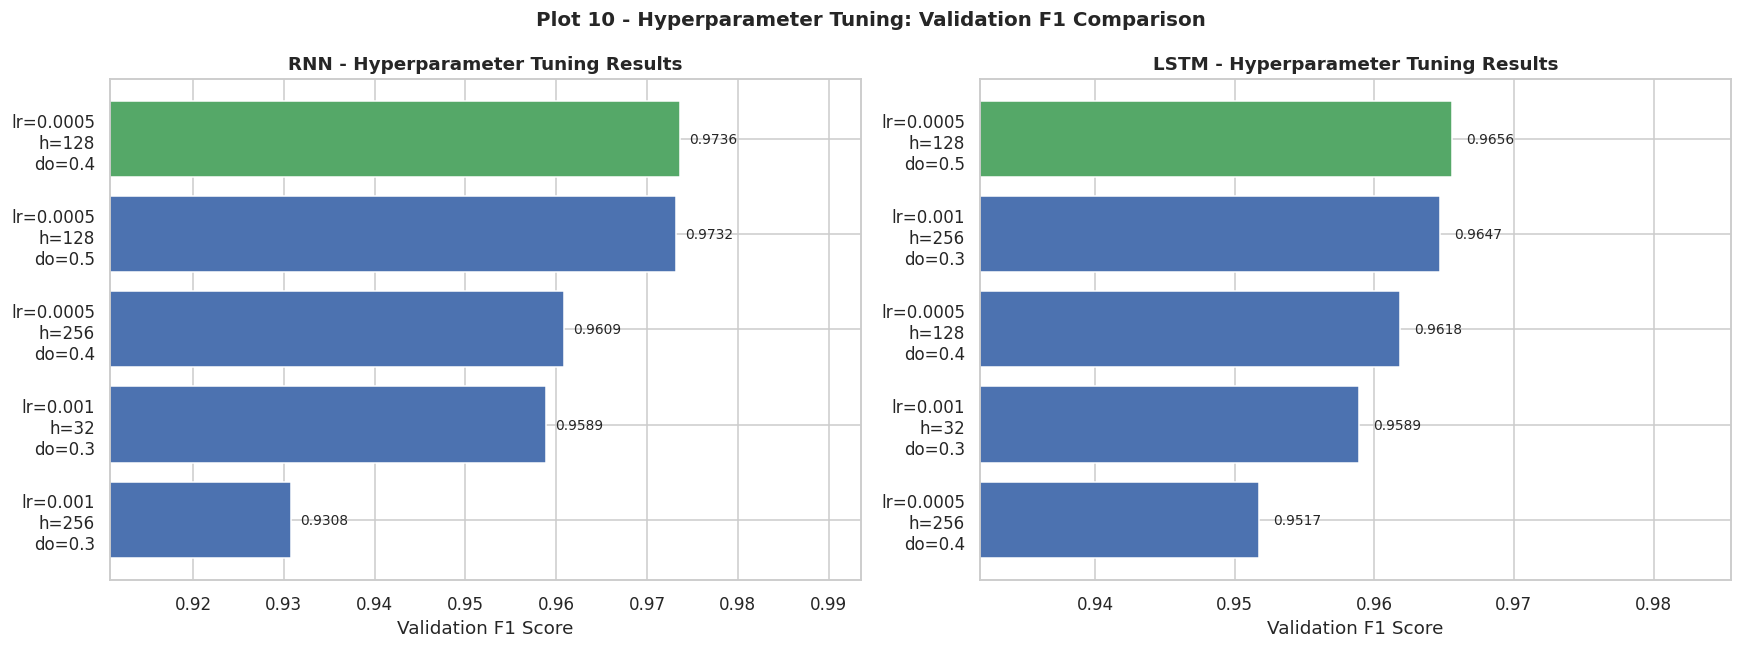

In [ ]:
# Visualize Tuning Results
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, arch in zip(axes, ['RNN', 'LSTM']):
    sub = df_tuning[df_tuning['arch'] == arch].copy()

    sub['config'] = sub.apply(
        lambda r: f"lr={r['learning_rate']}\nh={int(r['hidden_units'])}\ndo={r['dropout_rate']}",
        axis=1
    )

    sub = sub.sort_values('val_f1', ascending=True)

    colors = [
        palette[0] if v < sub['val_f1'].max() else palette[2]
        for v in sub['val_f1']
    ]

    bars = ax.barh(sub['config'], sub['val_f1'], color=colors, edgecolor='white')

    ax.set_xlabel('Validation F1 Score')
    ax.set_title(f'{arch} - Hyperparameter Tuning Results', fontsize=12, fontweight='bold')

    for bar, val in zip(bars, sub['val_f1']):
        ax.text(bar.get_width() + 0.001,
                bar.get_y() + bar.get_height()/2,
                f'{val:.4f}',
                va='center', fontsize=9)

    ax.set_xlim(sub['val_f1'].min() - 0.02, sub['val_f1'].max() + 0.02)

plt.suptitle('Plot 10 - Hyperparameter Tuning: Validation F1 Comparison',
             fontsize=13, fontweight='bold')
plt.tight_layout()
save_fig('10_hyperparameter_tuning')

In [ ]:
# Extract Best Configuration and Retrain
def get_best_config(arch):
    sub = df_tuning[df_tuning['arch'] == arch]
    best_row = sub.loc[sub['val_f1'].idxmax()]

    return {
        'learning_rate': best_row['learning_rate'],
        'hidden_units': int(best_row['hidden_units']),
        'dropout_rate': best_row['dropout_rate'],
        'batch_size': int(best_row['batch_size']),
    }


best_rnn_cfg = get_best_config('RNN')
best_lstm_cfg = get_best_config('LSTM')

print("Best RNN config :", best_rnn_cfg)
print("Best LSTM config:", best_lstm_cfg)

X_full_raw = X_tr_scaled
y_full = y_tr


def augment_and_append(X, y, aug_fraction=0.3, noise_std=0.02,
                       time_warp_max=0.05, seed=42):

    rng = np.random.default_rng(seed)
    N, T, C = X.shape

    n_aug = int(N * aug_fraction)
    aug_idx = rng.choice(N, size=n_aug, replace=False)

    X_new = X[aug_idx].copy()

    # Gaussian noise on first half
    X_new[:n_aug // 2] += noise_std * rng.standard_normal(X_new[:n_aug // 2].shape)

    # Time warp on second half
    orig_t = np.linspace(0, 1, T)

    for k in range(n_aug // 2, n_aug):
        distortion = rng.uniform(-time_warp_max, time_warp_max, size=T)
        warped_t = orig_t + np.cumsum(distortion)
        warped_t = (warped_t - warped_t[0]) / (warped_t[-1] - warped_t[0])

        for ch in range(C):
            X_new[k, :, ch] = np.interp(orig_t, warped_t, X_new[k, :, ch])

    X_out = np.concatenate([X, X_new], axis=0)
    y_out = np.concatenate([y, y[aug_idx]], axis=0)

    return X_out, y_out


X_full_aug, y_full_aug = augment_and_append(X_full_raw, y_full, seed=SEED)
y_full_aug = y_full_aug.astype(np.int64)


def make_full_ds(batch_size):
    return make_dataloader(
        X_full_aug.astype(np.float32),
        y_full_aug,
        batch_size,
        shuffle=True
    )

final_train_ds = make_full_ds(best_rnn_cfg['batch_size'])
final_val_ds   = val_ds
final_test_ds  = test_ds

# Post tuning RNN
rnn_model, rnn_optimizer = build_rnn(
    hidden_units=best_rnn_cfg['hidden_units'],
    dropout_rate=best_rnn_cfg['dropout_rate'],
    lr=best_rnn_cfg['learning_rate']
)

print("\nTraining post-tuning RNN")

hist_rnn_post_tuning = train_model(
    rnn_model,
    rnn_optimizer,
    final_train_ds,
    final_val_ds,
    epochs=configuration['epochs'],
    early_stop_cb=get_callbacks('rnn_post_tuning', monitor='val_loss'),
    lr_scheduler=None,
    verbose=1
)


# Post tuning LSTM
lstm_model, lstm_optimizer = build_lstm(
    hidden_units=best_lstm_cfg['hidden_units'],
    dropout_rate=best_lstm_cfg['dropout_rate'],
    lr=best_lstm_cfg['learning_rate']
)

print("\nTraining post-tuning LSTM")

hist_lstm_post_tuning = train_model(
    lstm_model,
    lstm_optimizer,
    final_train_ds,
    final_val_ds,
    epochs=configuration['epochs'],
    early_stop_cb=get_callbacks('lstm_post_tuning', monitor='val_loss'),
    lr_scheduler=None,  # strictly use tuned LR
    verbose=1
)

print("\nPost-tuning model training complete.")


Best RNN config : {'learning_rate': np.float64(0.0005), 'hidden_units': 128, 'dropout_rate': np.float64(0.4), 'batch_size': 128}
Best LSTM config: {'learning_rate': np.float64(0.0005), 'hidden_units': 128, 'dropout_rate': np.float64(0.5), 'batch_size': 128}

Training post-tuning RNN
Epoch   1/50 | loss=0.9276 acc=0.6269 | val_loss=0.4954 val_acc=0.7918 val_f1=0.7729
Epoch   2/50 | loss=0.4049 acc=0.8446 | val_loss=0.2787 val_acc=0.8973 val_f1=0.8963
Epoch   3/50 | loss=0.3138 acc=0.8776 | val_loss=0.1241 val_acc=0.9701 val_f1=0.9693
Epoch   4/50 | loss=0.2540 acc=0.9025 | val_loss=0.1310 val_acc=0.9542 val_f1=0.9545
Epoch   5/50 | loss=0.2241 acc=0.9124 | val_loss=0.2269 val_acc=0.9197 val_f1=0.9180
Epoch   6/50 | loss=0.2020 acc=0.9201 | val_loss=0.0762 val_acc=0.9720 val_f1=0.9728
Epoch   7/50 | loss=0.1851 acc=0.9260 | val_loss=0.1065 val_acc=0.9561 val_f1=0.9567
Epoch   8/50 | loss=0.1838 acc=0.9261 | val_loss=0.1517 val_acc=0.9533 val_f1=0.9560
Epoch   9/50 | loss=0.1682 acc=0.929

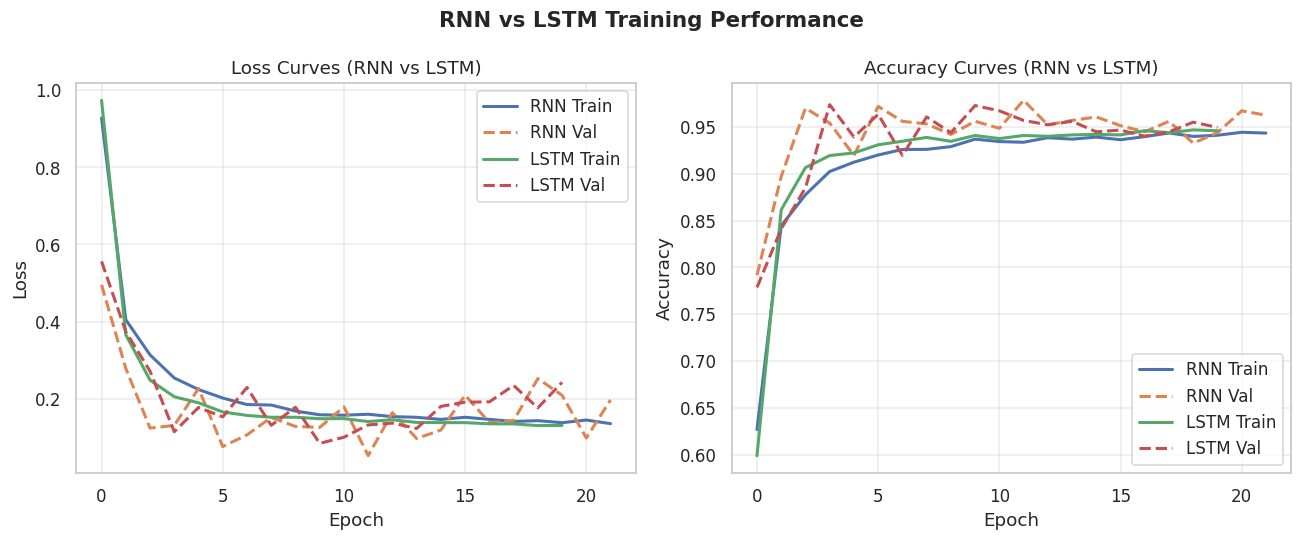

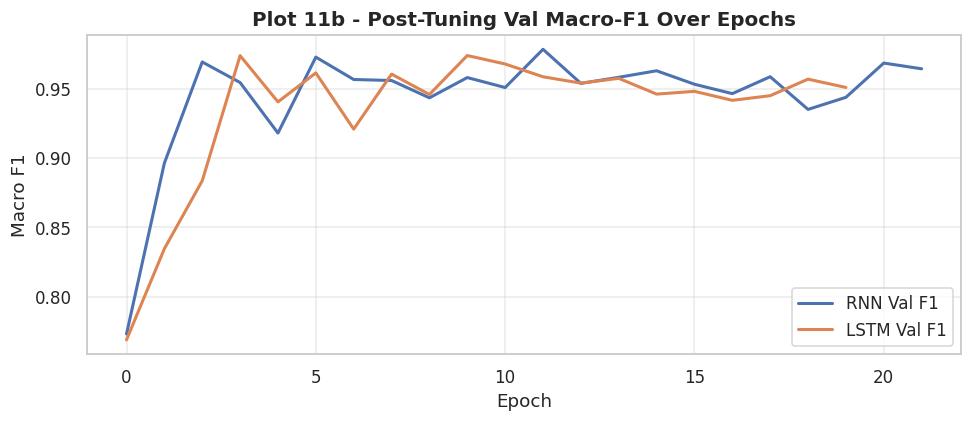

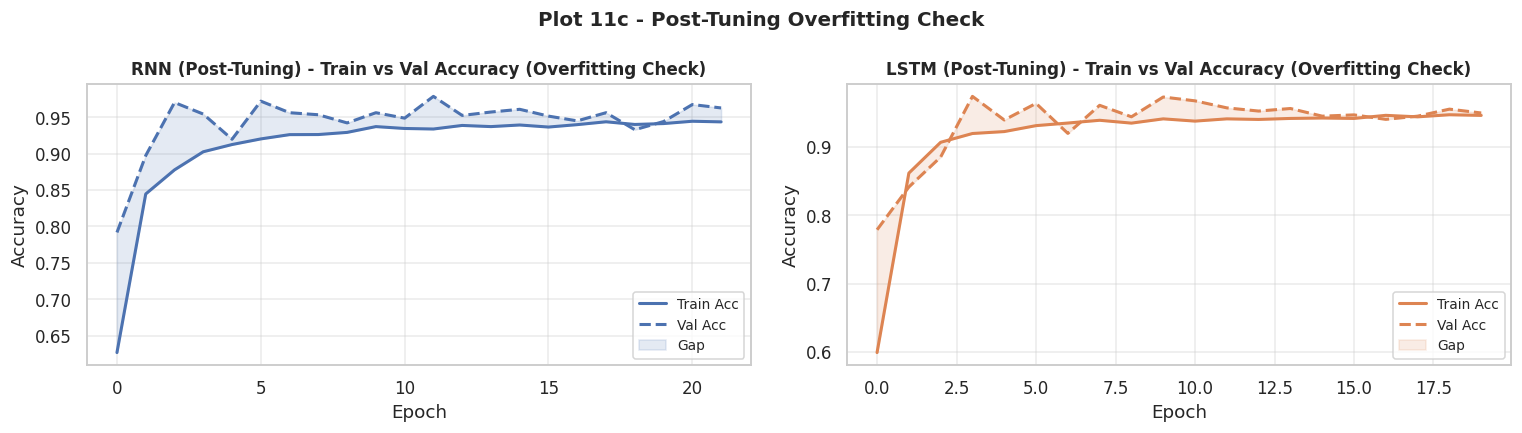

In [ ]:
# Plot 11: Post-Tuning Training Curves (Loss & Accuracy)
plot_training_history(hist_rnn_post_tuning, hist_lstm_post_tuning, '11_training_curves')

# Plot 11b: Post-Tuning Val F1 Over Epochs
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(hist_rnn_post_tuning['val_f1'],  label='RNN Val F1',  lw=2, color='#4C72B0')
ax.plot(hist_lstm_post_tuning['val_f1'], label='LSTM Val F1', lw=2, color='#DD8452')
ax.set_title('Plot 11b - Post-Tuning Val Macro-F1 Over Epochs', fontsize=13, fontweight='bold')
ax.set_xlabel('Epoch')
ax.set_ylabel('Macro F1')
ax.legend()
ax.grid(alpha=0.4)
plt.tight_layout()
save_fig('11b_post_tuning_val_f1')

# Plot 11c: Post-Tuning Overfitting Check (Train vs Val Gap)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for ax, hist, name, color in zip(
    axes,
    [hist_rnn_post_tuning, hist_lstm_post_tuning],
    ['RNN (Post-Tuning)', 'LSTM (Post-Tuning)'],
    ['#4C72B0', '#DD8452']
):
    gap = [tr - va for tr, va in zip(hist['accuracy'], hist['val_accuracy'])]
    ax.plot(hist['accuracy'],     label='Train Acc', lw=2, color=color)
    ax.plot(hist['val_accuracy'], label='Val Acc',   lw=2, color=color, linestyle='--')
    ax.fill_between(range(len(hist['accuracy'])),
                    hist['val_accuracy'],
                    hist['accuracy'],
                    alpha=0.15, color=color, label='Gap')
    ax.set_title(f'{name} - Train vs Val Accuracy (Overfitting Check)', fontsize=11, fontweight='bold')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Accuracy')
    ax.legend(fontsize=9)
    ax.grid(alpha=0.4)

plt.suptitle('Plot 11c - Post-Tuning Overfitting Check', fontsize=13, fontweight='bold')
plt.tight_layout()
save_fig('11c_post_tuning_overfit_check')

# Post-Tuning Model Evaluation

In [ ]:
def evaluate_model(model, model_name, X_test, y_test_int):
    model.eval()
    X_t = torch.tensor(X_test, dtype=torch.float32)
    with torch.no_grad():
        logits = model(X_t.to(DEVICE))
        y_pred_prob = torch.softmax(logits, dim=1).cpu().numpy()
    y_pred = np.argmax(y_pred_prob, axis=1)

    acc      = accuracy_score(y_test_int, y_pred)
    macro_f1 = f1_score(y_test_int, y_pred, average='macro')
    cm       = confusion_matrix(y_test_int, y_pred)
    report   = classification_report(y_test_int, y_pred,
                                     target_names=ACTIVITY_NAMES, digits=4)

    print(f"  {model_name}")
    print("------------------------------------------------------------")
    print(f"  Test Accuracy : {acc:.4f}")
    print(f"  Macro F1-Score: {macro_f1:.4f}")
    print(f"\nPer-Class Classification Report:\n")
    print(report)

    return acc, macro_f1, cm, y_pred

rnn_post_model = rnn_model
lstm_post_model = lstm_model

rnn_acc, rnn_f1, rnn_cm, rnn_pred = evaluate_model(
    rnn_post_model,
    'RNN (Post-Tuning)',
    X_te_scaled,
    y_test
)

lstm_acc, lstm_f1, lstm_cm, lstm_pred = evaluate_model(
    lstm_post_model,
    'LSTM (Post-Tuning)',
    X_te_scaled,
    y_test
)

  RNN (Post-Tuning)
------------------------------------------------------------
  Test Accuracy : 0.9169
  Macro F1-Score: 0.9165

Per-Class Classification Report:

                    precision    recall  f1-score   support

           WALKING     0.9548    0.9375    0.9461       496
  WALKING_UPSTAIRS     0.9116    0.9193    0.9154       471
WALKING_DOWNSTAIRS     0.9270    0.9976    0.9610       420
           SITTING     0.8533    0.7821    0.8162       491
          STANDING     0.8529    0.8722    0.8625       532
            LAYING     0.9963    1.0000    0.9981       537

          accuracy                         0.9169      2947
         macro avg     0.9160    0.9181    0.9165      2947
      weighted avg     0.9162    0.9169    0.9161      2947

  LSTM (Post-Tuning)
------------------------------------------------------------
  Test Accuracy : 0.9111
  Macro F1-Score: 0.9109

Per-Class Classification Report:

                    precision    recall  f1-score   support

   

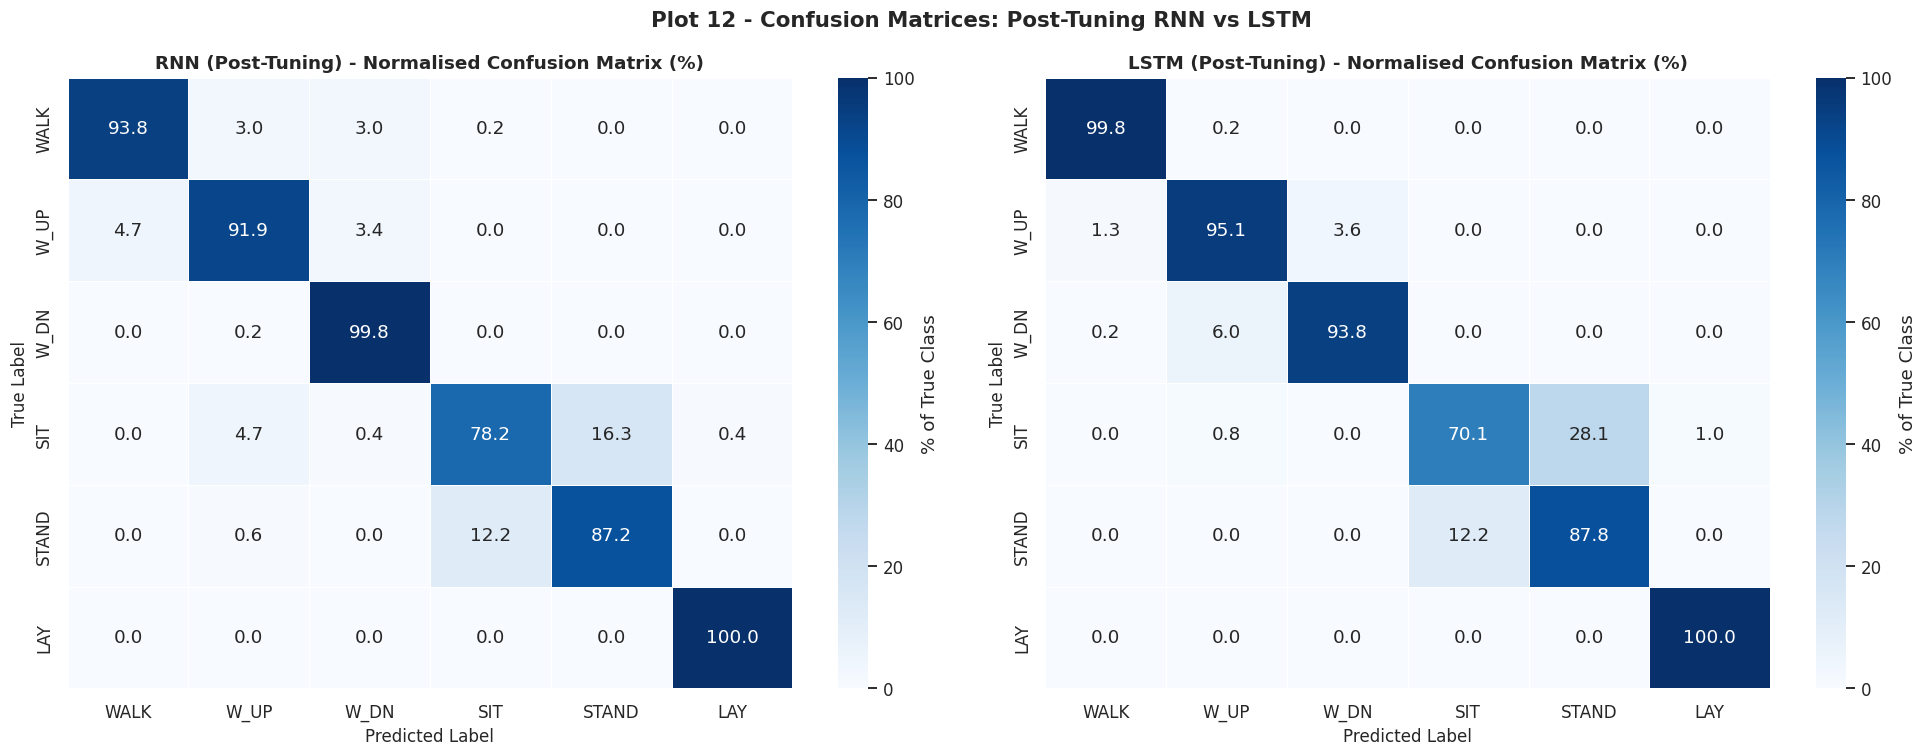

In [ ]:
# Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for ax, cm, name in zip(
    axes,
    [rnn_cm, lstm_cm],
    ['RNN (Post-Tuning)', 'LSTM (Post-Tuning)']
):
    row_sum = cm.sum(axis=1, keepdims=True)
    cm_norm = np.divide(cm, row_sum, where=row_sum != 0) * 100
    sns.heatmap(
        cm_norm,
        annot=True,
        fmt='.1f',
        cmap='Blues',
        xticklabels=SHORT_LABELS,
        yticklabels=SHORT_LABELS,
        linewidths=0.5,
        ax=ax,
        cbar_kws={'label': '% of True Class'}
    )
    ax.set_xlabel('Predicted Label', fontsize=11)
    ax.set_ylabel('True Label', fontsize=11)
    ax.set_title(f'{name} - Normalised Confusion Matrix (%)', fontsize=12, fontweight='bold')

plt.suptitle('Plot 12 - Confusion Matrices: Post-Tuning RNN vs LSTM', fontsize=14, fontweight='bold')
plt.tight_layout()
save_fig('12_post_tuning_confusion_matrices')

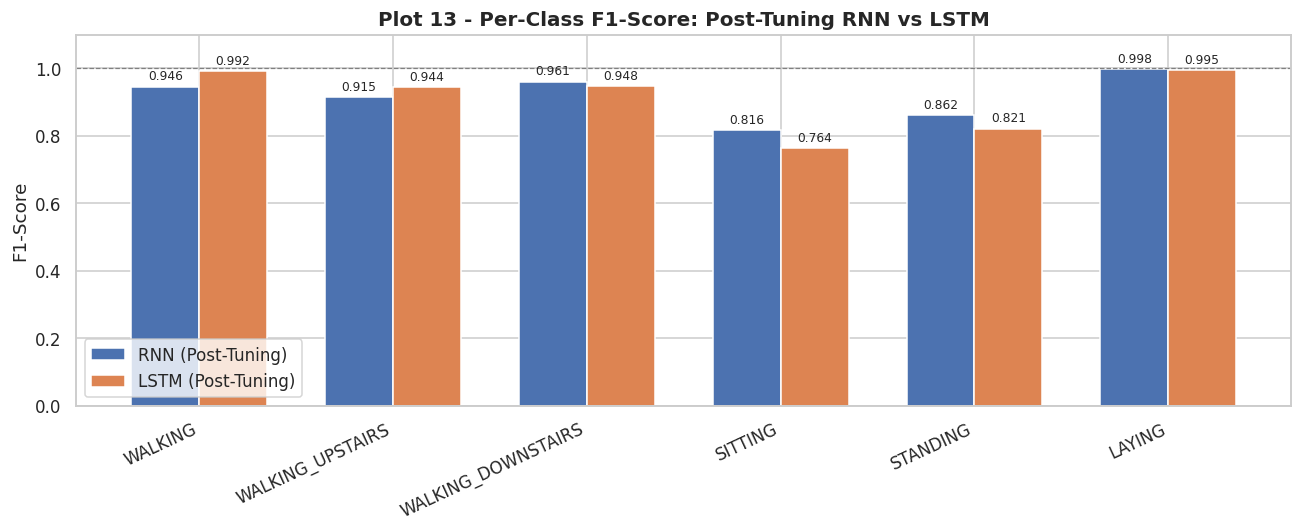

In [ ]:
# Per-class F1 Comparison Bar Chart
from sklearn.metrics import f1_score as _f1

rnn_per_class  = _f1(y_test, rnn_pred,  average=None)
lstm_per_class = _f1(y_test, lstm_pred, average=None)

x = np.arange(len(ACTIVITY_NAMES))
w = 0.35
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(x - w/2, rnn_per_class,  width=w, label='RNN (Post-Tuning)',  color='#4C72B0', edgecolor='white')
ax.bar(x + w/2, lstm_per_class, width=w, label='LSTM (Post-Tuning)', color='#DD8452', edgecolor='white')
ax.set_xticks(x)
ax.set_xticklabels(ACTIVITY_NAMES, rotation=25, ha='right')
ax.set_ylabel('F1-Score')
ax.set_ylim(0, 1.1)
ax.axhline(1.0, color='grey', lw=0.8, linestyle='--')
ax.legend()

# Annotate each bar with value
for xi, (rv, lv) in enumerate(zip(rnn_per_class, lstm_per_class)):
    ax.text(xi - w/2, rv + 0.02, f'{rv:.3f}', ha='center', fontsize=8)
    ax.text(xi + w/2, lv + 0.02, f'{lv:.3f}', ha='center', fontsize=8)

ax.set_title('Plot 13 - Per-Class F1-Score: Post-Tuning RNN vs LSTM', fontsize=13, fontweight='bold')
plt.tight_layout()
save_fig('13_post_tuning_per_class_f1')

##Demo

In [ ]:
MODEL_SAVE_DIR = 'saved_models'
os.makedirs(MODEL_SAVE_DIR, exist_ok=True)

models_to_save = {
    'rnn_baseline_model' : rnn_baseline_model,
    'lstm_baseline_model': lstm_baseline_model,
    'rnn_post_model'     : rnn_post_model,
    'lstm_post_model'    : lstm_post_model,
}

for name, model in models_to_save.items():
    path = os.path.join(MODEL_SAVE_DIR, f'{name}.pth')
    torch.save(model.state_dict(), path)

In [ ]:
#  SINGLE-SAMPLE INFERENCE DEMO
MODELS = [
    ('RNN  (Baseline)',    rnn_baseline_model),
    ('LSTM (Baseline)',    lstm_baseline_model),
    ('RNN  (Post-Tuning)', rnn_post_model),
    ('LSTM (Post-Tuning)', lstm_post_model),
]

BORDER      = '=' * 66
THIN_BORDER = '-' * 66

def _label(idx):
    return ACTIVITY_LABELS[idx + 1]

def _run_inference(model, sample_np):
    model.eval()
    x = torch.tensor(sample_np, dtype=torch.float32).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        probs = F.softmax(model(x), dim=1).cpu().numpy()[0]
    pred_idx = int(np.argmax(probs))
    return pred_idx, float(probs[pred_idx]) * 100, probs

def _prob_table(probs, true_idx, pred_idx):
    ranked = sorted(enumerate(probs), key=lambda x: x[1], reverse=True)
    lines  = [f"  {'Rank':<5} {'Activity':<22} {'Probability':>11}   Bar",
              '  ' + '-' * 56]
    for rank, (cls_idx, p) in enumerate(ranked, 1):
        bar    = chr(9608) * int(p * 20)
        marker = (' <- TRUE' if cls_idx == true_idx  else '') + \
                 (' <- PRED' if cls_idx == pred_idx  else '')
        lines.append(f"  {rank:<5} {_label(cls_idx):<22} {p*100:>9.2f}%   {bar}{marker}")
    return '\n'.join(lines)

while True:
    try:
        raw = input('\n  Enter a sample number (1 - 2947): ').strip()
        sample_id = int(raw)
        if not (1 <= sample_id <= 2947):
            print('    Out of range. Please enter a number between 1 and 2947.')
            continue
        break
    except ValueError:
        print('    Invalid input. Please enter a whole number.')

idx        = sample_id - 1
sample_np  = X_te_scaled[idx]
true_idx   = int(y_test[idx])
true_label = _label(true_idx)

try:
    subj_info = f'  Subject ID  : {subj_test[idx]}'
except NameError:
    subj_info = None

print(f'\n{BORDER}')
print(f"  {'UCI HAR - SINGLE SAMPLE INFERENCE DEMO (4 Models)':^62}")
print(BORDER)
print(f'  Sample ID   : {sample_id}  (array index {idx})')
if subj_info:
    print(subj_info)
print(f'  True Label  : {true_label}')
print(THIN_BORDER)

results = []
for model_name, model in MODELS:
    pred_idx, conf, probs = _run_inference(model, sample_np)
    verdict = 'CORRECT  ' if pred_idx == true_idx else 'INCORRECT'
    results.append((model_name, pred_idx, conf, probs, verdict))

    print(f'\n  MODEL : {model_name}')
    print(f"  {'─' * 44}")
    print(f'  Predicted   : {_label(pred_idx)}')
    print(f'  Confidence  : {conf:.2f}%')
    print(f'  Verdict     : {verdict}')
    print(f'\n  Class probabilities (ranked):')
    print(_prob_table(probs, true_idx, pred_idx))
    print(f'\n{THIN_BORDER}')

print(f"\n  {'SUMMARY':^62}")
print(f"  {'-' * 62}")
print(f"  {'Model':<26} {'Prediction':<22} {'Conf':>7}   Verdict")
print(f"  {'-' * 62}")
for model_name, pred_idx, conf, _, verdict in results:
    print(f'  {model_name:<26} {_label(pred_idx):<22} {conf:>6.1f}%   {verdict}')
print(f"  {'-' * 62}")

n_correct = sum(1 for _, pi, *_ in results if pi == true_idx)
all_agree = len(set(pi for _, pi, *_ in results)) == 1
print(f'\n  True Activity : {true_label}')
print(f'  Models correct: {n_correct} / {len(MODELS)}')
print(f"  Consensus     : {'All 4 models agree' if all_agree else 'Models disagree'}")
print(f'\n{BORDER}\n')